# VentiMorph-RelNet v2.8.1 — Ablation A4 — No stop-gradient guidance — Fold 3

Allows segmentation gradients to flow through the ventricle-guidance probabilities used by both relation refiners.

## Scientific protocol
- This is an **ablation experiment**, not a replacement for the frozen main v2.8.1 model.
- Uses the exact frozen patient split from the completed main experiment.
- Uses the same 60-epoch schedule, optimizer, learning rate, batch size, seed, and loss settings except for the one ablated component.
- Starts from scratch at E001 and targets E060 in one run.
- Ordinary early stopping remains disabled (`patience=999`) to match the completed main experiment.
- Best checkpoints are still saved.
- Locked-test evaluation is disabled. **Do not use the 20 locked-test patients for ablation selection.**

## Kaggle input
- Attach **only the original MS3SEG dataset**.
- Select **T4 GPU**.
- Use **Save Version → Save & Run All**.

Frozen split SHA-256: `d5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459`


In [1]:
# Kaggle dependency cell:
# !pip install -q nibabel surface-distance

In [2]:
from __future__ import annotations

import os, re, gc, json, math, random, warnings
from dataclasses import dataclass, asdict
from functools import lru_cache
from pathlib import Path
from typing import List, Tuple, Literal

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from scipy import ndimage
from sklearn.model_selection import train_test_split, StratifiedKFold

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision.transforms as T
import torchvision.transforms.functional as TF
from torchvision.transforms import InterpolationMode

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True

seed_everything()

# ------------------------------------------------------------------
# GPU compatibility check
# ------------------------------------------------------------------
GPU_COMPATIBLE = False
GPU_MESSAGE = ""

if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    capability = torch.cuda.get_device_capability(0)
    required_arch = f"sm_{capability[0]}{capability[1]}"
    compiled_arches = set(torch.cuda.get_arch_list())

    GPU_COMPATIBLE = required_arch in compiled_arches

    if GPU_COMPATIBLE:
        DEVICE = torch.device("cuda")
        GPU_MESSAGE = (
            f"Compatible GPU: {gpu_name}; capability={required_arch}; "
            f"PyTorch architectures={sorted(compiled_arches)}"
        )
    else:
        DEVICE = torch.device("cpu")
        GPU_MESSAGE = (
            f"Incompatible GPU: {gpu_name}; capability={required_arch}; "
            f"this PyTorch build supports {sorted(compiled_arches)}. "
            "For training, select a T4 GPU or another supported GPU in "
            "Kaggle Settings, restart the session, and Run All."
        )
else:
    DEVICE = torch.device("cpu")
    GPU_MESSAGE = (
        "CUDA is unavailable. Enable a compatible Kaggle GPU before training."
    )

print("Selected device:", DEVICE)
print(GPU_MESSAGE)

Selected device: cuda
Compatible GPU: Tesla T4; capability=sm_75; PyTorch architectures=['sm_100', 'sm_120', 'sm_70', 'sm_75', 'sm_80', 'sm_86', 'sm_90']


## Important GPU correction

The previous run selected a **Tesla P100 (`sm_60`)**, but the installed PyTorch build supported `sm_70` and newer CUDA architectures.

Before model training:

1. Open **Kaggle Notebook → Settings**.
2. Select **T4 GPU** or another GPU supported by the architecture list printed above.
3. Restart the session.
4. Run the notebook from the beginning.

The corrected notebook can continue dataset auditing on CPU, but it blocks training until a compatible GPU is active.

In [3]:
def discover_ms3seg_root():
    preferred_candidates = [
        Path(
            "/kaggle/input/datasets/saifsamiul/ms3seg/MS3SEG"
        ),
        Path(
            "/kaggle/input/ms3seg/MS3SEG"
        ),
        Path(
            "/kaggle/input/ms3seg"
        ),
    ]

    required_directories = {
        "MS_100_patient_preprocessed",
        "MS_100_patient_masks",
    }

    for candidate in preferred_candidates:
        if (
            candidate.exists()
            and required_directories.issubset({
                path.name
                for path in candidate.iterdir()
                if path.is_dir()
            })
        ):
            return candidate

    input_root = Path(
        "/kaggle/input"
    )

    if input_root.exists():
        for preprocessed_directory in input_root.rglob(
            "MS_100_patient_preprocessed"
        ):
            candidate = (
                preprocessed_directory.parent
            )

            if (
                candidate
                / "MS_100_patient_masks"
            ).exists():
                return candidate

    raise FileNotFoundError(
        "MS3SEG dataset root was not found. Add the same MS3SEG dataset "
        "through Kaggle Add Input and verify that it contains "
        "MS_100_patient_preprocessed and MS_100_patient_masks."
    )


DATA_ROOT = discover_ms3seg_root()
PREPROCESSED_DIR = (
    DATA_ROOT
    / "MS_100_patient_preprocessed"
)
MASKS_DIR = (
    DATA_ROOT
    / "MS_100_patient_masks"
)
MODEL_INPUT_DIR = (
    DATA_ROOT
    / "MS_100_model_input"
)

OUTPUT_DIR = Path("/kaggle/working/ventimorph_v281_ablation_a4_no_stopgrad_fold3")

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print(
    "Dataset root:",
    DATA_ROOT,
)
print(
    "Output directory:",
    OUTPUT_DIR,
)

Dataset root: /kaggle/input/datasets/saifsamiul/ms3seg/MS3SEG
Output directory: /kaggle/working/ventimorph_v281_ablation_a4_no_stopgrad_fold3


In [4]:
mask_roots = [p for p in MASKS_DIR.iterdir() if p.is_dir()]
print("Mask roots:", [p.name for p in mask_roots])

def select_mask_root(kind):
    if kind == "vent":
        matches = [p for p in mask_roots if "vent" in p.name.lower()]
    elif kind == "nwmh":
        matches = [p for p in mask_roots
                   if ("nwmh" in p.name.lower() or "normal" in p.name.lower())
                   and "abwmh" not in p.name.lower()
                   and "abnormal" not in p.name.lower()]
    else:
        matches = [p for p in mask_roots
                   if "abwmh" in p.name.lower() or "abnormal" in p.name.lower()]
    if len(matches) != 1:
        raise RuntimeError(f"Expected one {kind} mask root, found {matches}")
    return matches[0]

VENT_ROOT = select_mask_root("vent")
NWMH_ROOT = select_mask_root("nwmh")
ABWMH_ROOT = select_mask_root("abwmh")

Mask roots: ['nWMH_Masks', 'abWMH_Masks', 'Vent_Masks']


In [5]:
def find_unique_file(folder, patterns, description):
    found = []
    for pattern in patterns:
        found.extend(folder.glob(pattern))
    unique = []
    seen = set()
    for p in found:
        if p.is_file() and p not in seen:
            unique.append(p)
            seen.add(p)
    if len(unique) != 1:
        raise FileNotFoundError(
            f"{description}: expected 1 match in {folder}, found {len(unique)}: {unique}"
        )
    return unique[0]

patient_dirs = sorted(
    p for p in PREPROCESSED_DIR.iterdir()
    if p.is_dir() and re.fullmatch(r"\d{3}", p.name)
)

records = []
for pdir in patient_dirs:
    pid = pdir.name
    records.append({
        "patient_id": pid,
        "flair": str(find_unique_file(
            pdir, [f"{pid}_FLAIR.nii", f"{pid}_FLAIR.nii.gz"], f"{pid} FLAIR")),
        "t1": str(find_unique_file(
            pdir, [f"{pid}_T1WI_reg.nii", f"{pid}_T1WI_reg.nii.gz", "*T1*reg*.nii*"], f"{pid} T1")),
        "t2": str(find_unique_file(
            pdir, [f"{pid}_T2WI_reg.nii", f"{pid}_T2WI_reg.nii.gz", "*T2*reg*.nii*"], f"{pid} T2")),
        "vent": str(find_unique_file(
            VENT_ROOT / pid, [f"{pid}_Vent_Mask.nii", f"{pid}_Vent_Mask.nii.gz", "*Vent*Mask*.nii*"], f"{pid} vent")),
        "nwmh": str(find_unique_file(
            NWMH_ROOT / pid, [f"{pid}_nWMH_Mask.nii", f"{pid}_nWMH_Mask.nii.gz", "*nWMH*Mask*.nii*"], f"{pid} nWMH")),
        "abwmh": str(find_unique_file(
            ABWMH_ROOT / pid, [f"{pid}_abWMH_Mask.nii", f"{pid}_abWMH_Mask.nii.gz", "*abWMH*Mask*.nii*"], f"{pid} abWMH")),
    })

manifest = pd.DataFrame(records).sort_values("patient_id").reset_index(drop=True)
print("Patients:", len(manifest))
display(manifest.head())
if len(manifest) != 100:
    warnings.warn(f"Expected 100 patients, found {len(manifest)}")
manifest.to_csv(OUTPUT_DIR / "patient_manifest.csv", index=False)

Patients: 100


,patient_id,flair,t1,t2,vent,nwmh,abwmh
0,001,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
1,002,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
2,003,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
3,004,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...
4,005,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...,/kaggle/input/datasets/saifsamiul/ms3seg/MS3SE...


In [6]:
audit_rows = []
global_counts = np.zeros(4, dtype=np.int64)
overlaps = dict(vent_nwmh=0, vent_abwmh=0, nwmh_abwmh=0, triple=0)

for _, row in manifest.iterrows():
    imgs = {k: nib.load(row[k], mmap=True)
            for k in ["flair", "t1", "t2", "vent", "nwmh", "abwmh"]}
    shapes = {k: imgs[k].shape for k in imgs}
    same_shape = len(set(shapes.values())) == 1
    affine_ok = all(np.allclose(imgs[k].affine, imgs["flair"].affine, atol=1e-3)
                    for k in imgs)

    raw_masks = {
        key: np.asanyarray(imgs[key].dataobj)
        for key in ["vent", "nwmh", "abwmh"]
    }
    raw_values = {
        key: np.unique(raw_masks[key])
        for key in raw_masks
    }

    def is_two_level_binary_encoding(values):
        values = np.asarray(values)
        return (
            values.size in (1, 2)
            and np.isfinite(values).all()
            and np.isclose(values.min(), 0.0)
            and values.max() >= 0.0
        )

    binary_ok = all(
        is_two_level_binary_encoding(raw_values[key])
        for key in raw_values
    )
    strict_zero_one = all(
        set(np.round(raw_values[key], 8).tolist()).issubset({0.0, 1.0})
        for key in raw_values
    )

    # Convert any positive foreground code, including 255, to one.
    vent = raw_masks["vent"] > 0
    nwmh = raw_masks["nwmh"] > 0
    abwmh = raw_masks["abwmh"] > 0

    ov_vn = int((vent & nwmh).sum())
    ov_va = int((vent & abwmh).sum())
    ov_na = int((nwmh & abwmh).sum())
    ov_tr = int((vent & nwmh & abwmh).sum())
    overlaps["vent_nwmh"] += ov_vn
    overlaps["vent_abwmh"] += ov_va
    overlaps["nwmh_abwmh"] += ov_na
    overlaps["triple"] += ov_tr

    target = np.zeros(vent.shape, dtype=np.uint8)
    target[vent] = 1
    target[nwmh] = 2
    target[abwmh] = 3
    counts = np.bincount(target.ravel(), minlength=4)
    global_counts += counts

    spacing = tuple(float(v) for v in imgs["flair"].header.get_zooms()[:3])
    audit_rows.append({
        "patient_id": row.patient_id,
        "shape": str(shapes["flair"]),
        "spacing_x": spacing[0], "spacing_y": spacing[1], "spacing_z": spacing[2],
        "same_shape": same_shape,
        "affine_ok": affine_ok,
        "binary_masks": binary_ok,
        "strict_zero_one": strict_zero_one,
        "vent_raw_values": str(raw_values["vent"].tolist()),
        "nwmh_raw_values": str(raw_values["nwmh"].tolist()),
        "abwmh_raw_values": str(raw_values["abwmh"].tolist()),
        "vent_voxels": int(vent.sum()),
        "nwmh_voxels": int(nwmh.sum()),
        "abwmh_voxels": int(abwmh.sum()),
        "overlap_vent_nwmh": ov_vn,
        "overlap_vent_abwmh": ov_va,
        "overlap_nwmh_abwmh": ov_na,
        "overlap_triple": ov_tr,
    })

audit = pd.DataFrame(audit_rows)
audit.to_csv(OUTPUT_DIR / "integrity_audit.csv", index=False)
print("All shapes match:", audit.same_shape.all())
print("All affines match:", audit.affine_ok.all())
print("All masks have valid two-level binary encoding:", audit.binary_masks.all())
print("All masks use strict raw {0,1} values:", audit.strict_zero_one.all())
print("Overlap totals:", overlaps)

class_distribution = pd.DataFrame({
    "class_id": range(4),
    "class_name": ["Background", "Ventricle", "Normal_WMH", "Abnormal_WMH"],
    "voxels": global_counts,
    "percentage": 100.0 * global_counts / global_counts.sum(),
})
display(class_distribution)
class_distribution.to_csv(OUTPUT_DIR / "class_distribution.csv", index=False)

All shapes match: True
All affines match: True
All masks have valid two-level binary encoding: True
All masks use strict raw {0,1} values: False
Overlap totals: {'vent_nwmh': 2, 'vent_abwmh': 9, 'nwmh_abwmh': 227, 'triple': 0}


,class_id,class_name,voxels,percentage
0,0,Background,129192863,99.311166
1,1,Ventricle,523012,0.402042
2,2,Normal_WMH,151022,0.116091
3,3,Abnormal_WMH,222063,0.170701


## Mask-encoding diagnostic

Some NIfTI masks may use `{0,255}` or another two-level foreground encoding rather than strict `{0,1}` values. Such masks remain valid after conversion of every positive value to `1`. Any mask containing more than two finite levels is blocked from training.

In [7]:
nonstandard_masks = audit.loc[
    ~audit["strict_zero_one"],
    [
        "patient_id",
        "binary_masks",
        "vent_raw_values",
        "nwmh_raw_values",
        "abwmh_raw_values",
    ],
]

print("Patients with non-{0,1} raw encoding:", len(nonstandard_masks))
display(nonstandard_masks.head(30))

invalid_masks = audit.loc[~audit["binary_masks"]]
if len(invalid_masks) > 0:
    display(invalid_masks[
        [
            "patient_id",
            "vent_raw_values",
            "nwmh_raw_values",
            "abwmh_raw_values",
        ]
    ])
    raise ValueError(
        "At least one mask is not a valid two-level binary encoding. "
        "Inspect the displayed values before training."
    )

print(
    "All masks are valid after converting every positive "
    "foreground code to 1."
)

Patients with non-{0,1} raw encoding: 100


,patient_id,binary_masks,vent_raw_values,nwmh_raw_values,abwmh_raw_values
0,001,True,"[0.0, 0.9999999997671694]","[0.0, 254.9999999406282]","[0.0, 254.9999999406282]"
1,002,True,"[0.0, 0.9999999997671694]","[0.0, 254.9999999406282]","[0.0, 254.9999999406282]"
2,003,True,"[0.0, 0.9999999997671694]","[0.0, 254.9999999406282]","[0.0, 254.9999999406282]"
3,004,True,"[0.0, 0.9999999997671694]","[0.0, 254.9999999406282]","[0.0, 254.9999999406282]"
4,005,True,"[0.0, 0.9999999997671694]","[0.0, 254.9999999406282]","[0.0, 254.9999999406282]"
5,006,True,"[0.0, 0.9999999997671694]","[0.0, 254.9999999406282]","[0.0, 254.9999999406282]"
6,007,True,"[0.0, 0.9999999997671694]","[0.0, 254.9999999406282]","[0.0, 254.9999999406282]"
7,008,True,"[0.0, 0.9999999997671694]","[0.0, 254.9999999406282]","[0.0, 254.9999999406282]"
8,009,True,"[0.0, 0.9999999997671694]","[0.0, 254.9999999406282]","[0.0, 254.9999999406282]"
9,010,True,"[0.0, 0.9999999997671694]","[0.0, 254.9999999406282]","[0.0, 254.9999999406282]"


All masks are valid after converting every positive foreground code to 1.


In [8]:
# Patient statistics are retained for audit/reporting.
patient_stats = audit[
    ["patient_id", "vent_voxels", "nwmh_voxels", "abwmh_voxels",
     "spacing_x", "spacing_y", "spacing_z"]
].copy()

patient_stats["voxel_volume_mm3"] = (
    patient_stats.spacing_x
    * patient_stats.spacing_y
    * patient_stats.spacing_z
)

for name in ["vent", "nwmh", "abwmh"]:
    patient_stats[f"{name}_volume_ml"] = (
        patient_stats[f"{name}_voxels"]
        * patient_stats.voxel_volume_mm3
        / 1000.0
    )

# ------------------------------------------------------------------
# FROZEN 5-FOLD SPLIT
# ------------------------------------------------------------------
# This is the exact patient_level_5fold_split.csv produced by the
# completed v2.8.1 Fold-3 60-epoch run. Embedding it here prevents
# accidental regeneration of a different cross-validation partition.
FROZEN_SPLIT_SHA256 = "d5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459"

FROZEN_SPLIT_CSV = r"""patient_id,fold,role
002,0,train
003,0,train
004,0,train
005,0,train
009,0,train
010,0,train
011,0,train
012,0,train
013,0,train
015,0,train
016,0,train
019,0,train
020,0,train
021,0,train
022,0,train
025,0,train
026,0,train
028,0,train
029,0,train
030,0,train
031,0,train
032,0,train
035,0,train
037,0,train
038,0,train
039,0,train
043,0,train
044,0,train
045,0,train
047,0,train
049,0,train
050,0,train
051,0,train
052,0,train
054,0,train
056,0,train
058,0,train
059,0,train
060,0,train
061,0,train
063,0,train
065,0,train
066,0,train
067,0,train
068,0,train
069,0,train
073,0,train
075,0,train
077,0,train
078,0,train
080,0,train
081,0,train
082,0,train
083,0,train
084,0,train
087,0,train
090,0,train
091,0,train
092,0,train
093,0,train
094,0,train
096,0,train
097,0,train
098,0,train
001,0,val
007,0,val
017,0,val
018,0,val
023,0,val
034,0,val
048,0,val
053,0,val
062,0,val
064,0,val
070,0,val
072,0,val
086,0,val
089,0,val
095,0,val
099,0,val
001,1,train
002,1,train
003,1,train
004,1,train
005,1,train
007,1,train
009,1,train
011,1,train
012,1,train
015,1,train
016,1,train
017,1,train
018,1,train
021,1,train
022,1,train
023,1,train
025,1,train
029,1,train
031,1,train
032,1,train
034,1,train
035,1,train
037,1,train
038,1,train
039,1,train
043,1,train
044,1,train
045,1,train
047,1,train
048,1,train
050,1,train
052,1,train
053,1,train
056,1,train
060,1,train
062,1,train
063,1,train
064,1,train
065,1,train
066,1,train
067,1,train
069,1,train
070,1,train
072,1,train
073,1,train
075,1,train
077,1,train
078,1,train
080,1,train
081,1,train
082,1,train
083,1,train
084,1,train
086,1,train
087,1,train
089,1,train
090,1,train
092,1,train
093,1,train
094,1,train
095,1,train
096,1,train
098,1,train
099,1,train
010,1,val
013,1,val
019,1,val
020,1,val
026,1,val
028,1,val
030,1,val
049,1,val
051,1,val
054,1,val
058,1,val
059,1,val
061,1,val
068,1,val
091,1,val
097,1,val
001,2,train
002,2,train
003,2,train
005,2,train
007,2,train
009,2,train
010,2,train
012,2,train
013,2,train
015,2,train
016,2,train
017,2,train
018,2,train
019,2,train
020,2,train
021,2,train
023,2,train
026,2,train
028,2,train
029,2,train
030,2,train
032,2,train
034,2,train
035,2,train
037,2,train
038,2,train
043,2,train
044,2,train
047,2,train
048,2,train
049,2,train
051,2,train
052,2,train
053,2,train
054,2,train
056,2,train
058,2,train
059,2,train
060,2,train
061,2,train
062,2,train
063,2,train
064,2,train
066,2,train
067,2,train
068,2,train
070,2,train
072,2,train
075,2,train
078,2,train
080,2,train
083,2,train
084,2,train
086,2,train
087,2,train
089,2,train
090,2,train
091,2,train
092,2,train
095,2,train
096,2,train
097,2,train
098,2,train
099,2,train
004,2,val
011,2,val
022,2,val
025,2,val
031,2,val
039,2,val
045,2,val
050,2,val
065,2,val
069,2,val
073,2,val
077,2,val
081,2,val
082,2,val
093,2,val
094,2,val
001,3,train
002,3,train
003,3,train
004,3,train
007,3,train
009,3,train
010,3,train
011,3,train
012,3,train
013,3,train
016,3,train
017,3,train
018,3,train
019,3,train
020,3,train
022,3,train
023,3,train
025,3,train
026,3,train
028,3,train
029,3,train
030,3,train
031,3,train
034,3,train
035,3,train
037,3,train
038,3,train
039,3,train
045,3,train
048,3,train
049,3,train
050,3,train
051,3,train
052,3,train
053,3,train
054,3,train
056,3,train
058,3,train
059,3,train
061,3,train
062,3,train
064,3,train
065,3,train
068,3,train
069,3,train
070,3,train
072,3,train
073,3,train
077,3,train
080,3,train
081,3,train
082,3,train
083,3,train
086,3,train
087,3,train
089,3,train
090,3,train
091,3,train
092,3,train
093,3,train
094,3,train
095,3,train
097,3,train
099,3,train
005,3,val
015,3,val
021,3,val
032,3,val
043,3,val
044,3,val
047,3,val
060,3,val
063,3,val
066,3,val
067,3,val
075,3,val
078,3,val
084,3,val
096,3,val
098,3,val
001,4,train
004,4,train
005,4,train
007,4,train
010,4,train
011,4,train
013,4,train
015,4,train
017,4,train
018,4,train
019,4,train
020,4,train
021,4,train
022,4,train
023,4,train
025,4,train
026,4,train
028,4,train
030,4,train
031,4,train
032,4,train
034,4,train
039,4,train
043,4,train
044,4,train
045,4,train
047,4,train
048,4,train
049,4,train
050,4,train
051,4,train
053,4,train
054,4,train
058,4,train
059,4,train
060,4,train
061,4,train
062,4,train
063,4,train
064,4,train
065,4,train
066,4,train
067,4,train
068,4,train
069,4,train
070,4,train
072,4,train
073,4,train
075,4,train
077,4,train
078,4,train
081,4,train
082,4,train
084,4,train
086,4,train
089,4,train
091,4,train
093,4,train
094,4,train
095,4,train
096,4,train
097,4,train
098,4,train
099,4,train
002,4,val
003,4,val
009,4,val
012,4,val
016,4,val
029,4,val
035,4,val
037,4,val
038,4,val
052,4,val
056,4,val
080,4,val
083,4,val
087,4,val
090,4,val
092,4,val
006,-1,test
008,-1,test
014,-1,test
024,-1,test
027,-1,test
033,-1,test
036,-1,test
040,-1,test
041,-1,test
042,-1,test
046,-1,test
055,-1,test
057,-1,test
071,-1,test
074,-1,test
076,-1,test
079,-1,test
085,-1,test
088,-1,test
100,-1,test
"""

import io
import hashlib

actual_split_sha256 = hashlib.sha256(
    FROZEN_SPLIT_CSV.encode("utf-8")
).hexdigest()

if actual_split_sha256 != FROZEN_SPLIT_SHA256:
    raise RuntimeError(
        "Embedded frozen split checksum mismatch. "
        "Do not train because the cross-validation split may have changed."
    )

split_df = pd.read_csv(
    io.StringIO(FROZEN_SPLIT_CSV),
    dtype={"patient_id": str},
)

# Preserve three-digit patient IDs.
split_df["patient_id"] = split_df["patient_id"].str.zfill(3)
manifest["patient_id"] = manifest["patient_id"].astype(str).str.zfill(3)

manifest_ids = set(manifest["patient_id"])
split_ids = set(split_df["patient_id"])

if manifest_ids != split_ids:
    missing_from_split = sorted(manifest_ids - split_ids)
    missing_from_dataset = sorted(split_ids - manifest_ids)
    raise RuntimeError(
        "MS3SEG patient IDs do not match the frozen Fold-3 split. "
        f"Missing from split={missing_from_split}; "
        f"missing from dataset={missing_from_dataset}"
    )

# Validate the expected 80-development / 20-locked-test structure.
test_rows = split_df[split_df["role"] == "test"]
if test_rows["patient_id"].nunique() != 20:
    raise RuntimeError("Frozen split must contain exactly 20 locked-test patients.")

for fold_number in range(5):
    fold_rows = split_df[split_df["fold"] == fold_number]
    train_count = fold_rows.loc[
        fold_rows["role"] == "train", "patient_id"
    ].nunique()
    val_count = fold_rows.loc[
        fold_rows["role"] == "val", "patient_id"
    ].nunique()
    if train_count != 64 or val_count != 16:
        raise RuntimeError(
            f"Fold {fold_number} has unexpected counts: "
            f"train={train_count}, val={val_count}"
        )

split_df.to_csv(
    OUTPUT_DIR / "patient_level_5fold_split.csv",
    index=False,
)
patient_stats.to_csv(
    OUTPUT_DIR / "patient_burden_statistics.csv",
    index=False,
)

print("Frozen split checksum:", actual_split_sha256)
print("Frozen split source: completed v2.8.1 Fold-3 FULL60 run")
print("Development patients: 80")
print("Locked test patients: 20")
print("Fold 3 will use 64 training + 16 validation patients.")


Frozen split checksum: d5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459
Frozen split source: completed v2.8.1 Fold-3 FULL60 run
Development patients: 80
Locked test patients: 20
Fold 3 will use 64 training + 16 validation patients.


In [9]:
# The split is deliberately frozen from Fold 3, not rediscovered or regenerated.
split_summary = (
    split_df.groupby(["fold", "role"])["patient_id"]
    .nunique()
    .unstack(fill_value=0)
)
print("Frozen five-fold patient split:")
display(split_summary)
print("Current training fold: 1")
print("Locked-test evaluation remains disabled.")


Frozen five-fold patient split:


role,test,train,val
fold,,,
-1,20,0,0
0,0,64,16
1,0,64,16
2,0,64,16
3,0,64,16
4,0,64,16


Current training fold: 1
Locked-test evaluation remains disabled.


In [10]:
@lru_cache(maxsize=48)
def load_volume(path):
    return np.asarray(nib.load(path, mmap=True).dataobj, dtype=np.float32)

@lru_cache(maxsize=36)
def load_normalized_volume(path):
    arr = load_volume(path).copy()
    finite = np.isfinite(arr)
    nz = finite & (np.abs(arr) > 1e-6)
    if nz.sum() < 100:
        return np.nan_to_num(arr).astype(np.float32)
    low, high = np.percentile(arr[nz], [0.5, 99.5])
    high = max(high, low + 1.0)
    arr = np.clip(arr, low, high)
    arr = (arr - arr[nz].mean()) / (arr[nz].std() + 1e-6)
    arr[~finite] = 0.0
    return arr.astype(np.float32)

@lru_cache(maxsize=48)
def load_binary_mask(path):
    return (load_volume(path) > 0).astype(np.uint8)

def compose_target(row):
    vent = load_binary_mask(row.vent)
    nwmh = load_binary_mask(row.nwmh)
    abwmh = load_binary_mask(row.abwmh)
    target = np.zeros(vent.shape, dtype=np.uint8)
    target[vent > 0] = 1
    target[nwmh > 0] = 2
    target[abwmh > 0] = 3
    return target

@lru_cache(maxsize=120)
def relation_band_volume(vent_path):
    img = nib.load(vent_path, mmap=True)
    vent = np.asarray(img.dataobj) > 0.5
    spacing = img.header.get_zooms()[:2]
    bands = np.zeros_like(vent, dtype=np.uint8)
    for z in range(vent.shape[2]):
        dist = ndimage.distance_transform_edt(~vent[:, :, z], sampling=spacing)
        band = np.full(dist.shape, 2, dtype=np.uint8)
        band[dist <= 10.0] = 1
        band[dist <= 3.0] = 0
        bands[:, :, z] = band
    return bands

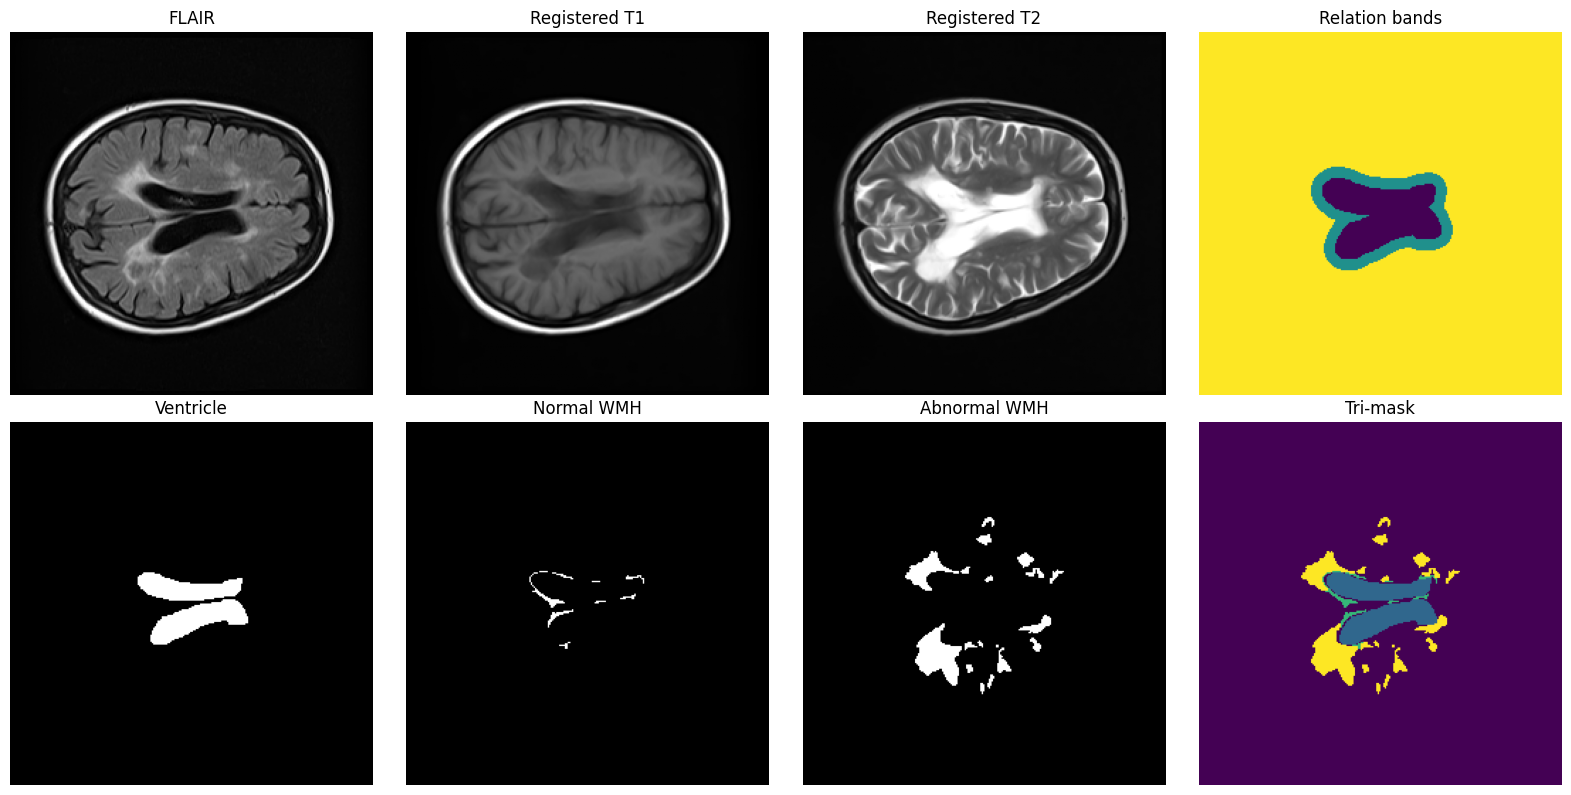

In [11]:
manifest_by_id = manifest.set_index("patient_id")
sample_pid = patient_stats.sort_values("abwmh_voxels", ascending=False).iloc[0].patient_id
row = manifest_by_id.loc[sample_pid]
flair, t1, t2 = [load_normalized_volume(row[k]) for k in ["flair", "t1", "t2"]]
target = compose_target(row)
bands = relation_band_volume(row.vent)
z = int(np.argmax((target == 3).sum(axis=(0, 1))))

fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for a, im, title in zip(
    ax.ravel(),
    [flair[:, :, z], t1[:, :, z], t2[:, :, z], bands[:, :, z],
     target[:, :, z] == 1, target[:, :, z] == 2, target[:, :, z] == 3, target[:, :, z]],
    ["FLAIR", "Registered T1", "Registered T2", "Relation bands",
     "Ventricle", "Normal WMH", "Abnormal WMH", "Tri-mask"]
):
    a.imshow(im, cmap="gray" if title != "Tri-mask" and title != "Relation bands" else "viridis")
    a.set_title(title)
    a.axis("off")
plt.tight_layout()
plt.show()

In [12]:
class MS3SEGVentiMorphDataset(Dataset):
    def __init__(
        self,
        manifest_df,
        patient_ids,
        augment=False,
        include_empty=True,
    ):
        self.manifest = manifest_df.set_index(
            "patient_id"
        )

        self.patient_ids = [
            str(value).zfill(
                3
            )
            for value in patient_ids
        ]

        self.augment = bool(
            augment
        )

        self.samples = []
        self.sample_weights = []
        self.sample_info = []

        for patient_id in self.patient_ids:
            row = self.manifest.loc[
                patient_id
            ]

            target = compose_target(
                row
            )

            for slice_index in range(
                target.shape[
                    2
                ]
            ):
                current_target = target[
                    :,
                    :,
                    slice_index,
                ]

                ventricle_pixels = int(
                    (
                        current_target
                        == 1
                    ).sum()
                )

                normal_pixels = int(
                    (
                        current_target
                        == 2
                    ).sum()
                )

                abnormal_pixels = int(
                    (
                        current_target
                        == 3
                    ).sum()
                )

                total_wmh_pixels = (
                    normal_pixels
                    + abnormal_pixels
                )

                if (
                    include_empty
                    or (
                        ventricle_pixels
                        + total_wmh_pixels
                    )
                    > 0
                ):
                    small_wmh = (
                        total_wmh_pixels
                        > 0
                        and total_wmh_pixels
                        <= 64
                    )

                    if small_wmh:
                        sample_weight = 2.5
                        group = "small_wmh"
                    elif total_wmh_pixels > 0:
                        sample_weight = 2.0
                        group = "wmh"
                    elif ventricle_pixels > 0:
                        sample_weight = 1.25
                        group = "ventricle_only"
                    else:
                        sample_weight = 1.0
                        group = "background"

                    self.samples.append(
                        (
                            patient_id,
                            slice_index,
                        )
                    )

                    self.sample_weights.append(
                        float(
                            sample_weight
                        )
                    )

                    self.sample_info.append({
                        "patient_id": patient_id,
                        "slice_index": slice_index,
                        "group": group,
                        "ventricle_pixels": ventricle_pixels,
                        "normal_pixels": normal_pixels,
                        "abnormal_pixels": abnormal_pixels,
                        "total_wmh_pixels": total_wmh_pixels,
                    })

    def __len__(self):
        return len(
            self.samples
        )

    @staticmethod
    def triplet(
        volume,
        slice_index,
    ):
        depth = volume.shape[
            2
        ]

        indices = [
            max(
                0,
                slice_index
                - 1,
            ),
            slice_index,
            min(
                depth
                - 1,
                slice_index
                + 1,
            ),
        ]

        return np.stack(
            [
                volume[
                    :,
                    :,
                    index,
                ]
                for index in indices
            ],
            axis=0,
        )

    def _augment(
        self,
        image,
        target,
        region,
    ):
        if random.random() < 0.5:
            image = torch.flip(
                image,
                dims=[
                    2,
                ],
            )

            target = torch.flip(
                target,
                dims=[
                    1,
                ],
            )

            region = torch.flip(
                region,
                dims=[
                    1,
                ],
            )

        if random.random() < 0.60:
            (
                angle,
                translate,
                scale,
                shear,
            ) = T.RandomAffine.get_params(
                degrees=(
                    -8.0,
                    8.0,
                ),
                translate=(
                    0.02,
                    0.02,
                ),
                scale_ranges=(
                    0.97,
                    1.03,
                ),
                shears=None,
                img_size=[
                    image.shape[
                        1
                    ],
                    image.shape[
                        2
                    ],
                ],
            )

            image = TF.affine(
                image,
                angle,
                translate,
                scale,
                shear,
                interpolation=(
                    InterpolationMode.BILINEAR
                ),
                fill=0.0,
            )

            target = TF.affine(
                target
                .unsqueeze(
                    0
                )
                .float(),
                angle,
                translate,
                scale,
                shear,
                interpolation=(
                    InterpolationMode.NEAREST
                ),
                fill=0.0,
            ).squeeze(
                0
            ).long()

            region = TF.affine(
                region
                .unsqueeze(
                    0
                )
                .float(),
                angle,
                translate,
                scale,
                shear,
                interpolation=(
                    InterpolationMode.NEAREST
                ),
                fill=2.0,
            ).squeeze(
                0
            ).long()

        for start in (
            0,
            3,
            6,
        ):
            modality = image[
                start:start
                + 3
            ]

            modality = (
                modality
                * random.uniform(
                    0.95,
                    1.05,
                )
                + random.uniform(
                    -0.05,
                    0.05,
                )
            )

            if random.random() < 0.15:
                modality = (
                    modality
                    + torch.randn_like(
                        modality
                    )
                    * 0.015
                )

            image[
                start:start
                + 3
            ] = modality

        return (
            image,
            target,
            region,
        )

    def __getitem__(
        self,
        index,
    ):
        (
            patient_id,
            slice_index,
        ) = self.samples[
            index
        ]

        row = self.manifest.loc[
            patient_id
        ]

        flair = load_normalized_volume(
            row.flair
        )

        t1 = load_normalized_volume(
            row.t1
        )

        t2 = load_normalized_volume(
            row.t2
        )

        image = np.concatenate(
            [
                self.triplet(
                    flair,
                    slice_index,
                ),
                self.triplet(
                    t1,
                    slice_index,
                ),
                self.triplet(
                    t2,
                    slice_index,
                ),
            ],
            axis=0,
        )

        target = compose_target(
            row
        )[
            :,
            :,
            slice_index,
        ]

        region = relation_band_volume(
            row.vent
        )[
            :,
            :,
            slice_index,
        ]

        image = torch.from_numpy(
            image.copy()
        ).float()

        target = torch.from_numpy(
            target.copy()
        ).long()

        region = torch.from_numpy(
            region.copy()
        ).long()

        if self.augment:
            (
                image,
                target,
                region,
            ) = self._augment(
                image,
                target,
                region,
            )

        return {
            "image": image,
            "target": target,
            "region_band": region,
            "patient_id": patient_id,
            "slice_index": slice_index,
        }

In [13]:
class ConvNormAct(nn.Module):
    def __init__(self, in_ch, out_ch, k=3, stride=1, groups=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, k, stride=stride, padding=k//2, groups=groups, bias=False),
            nn.GroupNorm(min(8, out_ch), out_ch),
            nn.SiLU(inplace=True),
        )
    def forward(self, x): return self.net(x)

class ResidualBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.c1 = ConvNormAct(ch, ch)
        self.c2 = nn.Sequential(nn.Conv2d(ch, ch, 3, padding=1, bias=False),
                                nn.GroupNorm(min(8, ch), ch))
        self.act = nn.SiLU(inplace=True)
    def forward(self, x): return self.act(x + self.c2(self.c1(x)))

class SE(nn.Module):
    def __init__(self, ch, r=8):
        super().__init__()
        h = max(8, ch // r)
        self.net = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(ch, h, 1),
                                 nn.SiLU(inplace=True), nn.Conv2d(h, ch, 1), nn.Sigmoid())
    def forward(self, x): return x * self.net(x)

class ModalityStem(nn.Module):
    def __init__(self, out_ch):
        super().__init__()
        self.net = nn.Sequential(ConvNormAct(3, out_ch), ResidualBlock(out_ch), SE(out_ch))
    def forward(self, x): return self.net(x)

def _safe_groups(channels, preferred=8):
    for g in (preferred, 4, 2, 1):
        if channels % g == 0:
            return g
    return 1

class ModalityGatedFusion(nn.Module):
    def __init__(self, ch):
        super().__init__()
        hidden = max(8, ch // 2)
        self.gate = nn.Sequential(
            nn.Conv2d(ch * 3, hidden, 1, bias=False),
            nn.GroupNorm(_safe_groups(hidden), hidden),
            nn.SiLU(inplace=True),
            nn.Conv2d(hidden, 3, 1),
        )
        self.refine = ResidualBlock(ch)
    def forward(self, f, t1, t2):
        # Per-pixel modality gate (was: one global-average-pooled scalar
        # weight per modality per sample). Lets FLAIR/T2 dominate locally
        # around WMH and T1 dominate near ventricle boundaries instead of
        # blending all three modalities with a single whole-image weight.
        stacked = torch.cat([f, t1, t2], 1)
        w = torch.softmax(self.gate(stacked), 1)
        fused = w[:, 0:1] * f + w[:, 1:2] * t1 + w[:, 2:3] * t2
        pooled_weights = w.mean(dim=(2, 3))
        return self.refine(fused), pooled_weights

class DownBlock(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.net = nn.Sequential(ConvNormAct(i, o, stride=2), ResidualBlock(o))
    def forward(self, x): return self.net(x)

class UpBlock(nn.Module):
    def __init__(self, i, s, o):
        super().__init__()
        self.net = nn.Sequential(ConvNormAct(i + s, o), ResidualBlock(o))
    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return self.net(torch.cat([x, skip], 1))

class AdaptiveAnisotropicContext(nn.Module):
    def __init__(self, ch):
        super().__init__()
        b = ch // 4
        self.reduce = ConvNormAct(ch, b, 1)
        self.branches = nn.ModuleList([
            nn.Sequential(nn.Conv2d(b, b, 3, padding=d, dilation=d, groups=b, bias=False),
                          nn.GroupNorm(min(8, b), b), nn.SiLU(inplace=True))
            for d in (1, 2, 4, 6)
        ])
        self.mix = nn.Sequential(nn.Conv2d(b * 4, ch, 1, bias=False),
                                 nn.GroupNorm(min(8, ch), ch), nn.SiLU(inplace=True))
        self.se = SE(ch)
    def forward(self, x):
        r = self.reduce(x)
        y = self.se(self.mix(torch.cat([b(r) for b in self.branches], 1)))
        return x + y

In [14]:
class VentiMorphRefiner(nn.Module):
    def __init__(
        self,
        ch,
        mode: Literal["none", "vent", "distance", "directional"],
        max_residual: float = 0.25,
        stop_gradient_guidance: bool = True,
    ):
        super().__init__()
        self.mode = mode
        self.max_residual = float(max_residual)
        self.stop_gradient_guidance = bool(stop_gradient_guidance)
        self.vent_head = nn.Conv2d(ch, 1, 1)
        extras = {"none": 0, "vent": 1, "distance": 5, "directional": 9}[mode]
        self.orientation_head = nn.Conv2d(ch, 2, 1) if mode == "directional" else None
        self.refine = nn.Identity() if mode == "none" else nn.Sequential(
            ConvNormAct(ch + extras, ch), ResidualBlock(ch)
        )

        # Exact identity at initialization + hard amplitude cap.
        self.correction_gate = nn.Conv2d(ch, ch, 1) if mode != "none" else None
        if self.correction_gate is not None:
            nn.init.zeros_(self.correction_gate.weight)
            nn.init.zeros_(self.correction_gate.bias)

        sx = torch.tensor([[-1.,0.,1.],[-2.,0.,2.],[-1.,0.,1.]]).view(1,1,3,3)
        sy = torch.tensor([[-1.,-2.,-1.],[0.,0.,0.],[1.,2.,1.]]).view(1,1,3,3)
        self.register_buffer("sobel_x", sx)
        self.register_buffer("sobel_y", sy)

    def forward(self, feat):
        v_logit = self.vent_head(feat)
        v = torch.sigmoid(v_logit)
        relation = {"vent_logits": v_logit, "vent_prob": v}

        if self.mode == "none":
            return feat, relation

        # v2.8.1: segmentation refinement consumes the current anatomical
        # prediction but does not back-propagate its segmentation gradient
        # through the ventricle head. The ventricle head remains trainable
        # through the explicit auxiliary ventricle loss.
        guide_v = v.detach() if self.stop_gradient_guidance else v

        if self.mode == "vent":
            correction = self.correction_gate(
                self.refine(torch.cat([feat, guide_v], 1))
            )
            return feat + torch.tanh(correction) * self.max_residual, relation

        e1 = F.max_pool2d(guide_v, 7, 1, 3)
        e2 = F.max_pool2d(guide_v, 21, 1, 10)
        near = torch.clamp(e1 - guide_v, 0, 1)
        mid = torch.clamp(e2 - e1, 0, 1)
        far = torch.clamp(1 - e2, 0, 1)
        dist = 0.2 * near + 0.6 * mid + far
        relation.update({"near": near, "mid": mid, "far": far, "soft_distance": dist})
        extras = [guide_v, near, mid, far, dist]

        if self.mode == "directional":
            normal = torch.cat([
                F.conv2d(dist, self.sobel_x, padding=1),
                F.conv2d(dist, self.sobel_y, padding=1),
            ], 1)
            normal = F.normalize(normal, dim=1, eps=1e-6)
            orient = F.normalize(self.orientation_head(feat), dim=1, eps=1e-6)
            radial = torch.abs((normal * orient).sum(1, keepdim=True))
            tangential = 1 - radial
            relation.update({
                "normal_x": normal[:,0:1], "normal_y": normal[:,1:2],
                "orientation_x": orient[:,0:1], "orientation_y": orient[:,1:2],
                "radial": radial, "tangential": tangential,
            })
            extras += [normal[:,0:1], normal[:,1:2], radial, tangential]

        correction = self.correction_gate(
            self.refine(torch.cat([feat] + extras, 1))
        )
        return feat + torch.tanh(correction) * self.max_residual, relation


class RelationConditionedPrototypeBank(nn.Module):
    # Retained only for later ablation work; disabled in the v2.8.1 primary run.
    def __init__(self, dim=32, temperature=0.1):
        super().__init__()
        self.temperature = temperature
        self.prototypes = nn.Parameter(F.normalize(torch.randn(2, 3, dim), dim=-1))

    def loss(self, embedding, target, region, max_samples=4096):
        feat = embedding.permute(0, 2, 3, 1)
        idx = ((target == 2) | (target == 3)).nonzero(as_tuple=False)
        if idx.numel() == 0:
            return embedding.sum() * 0
        if idx.shape[0] > max_samples:
            idx = idx[torch.randperm(idx.shape[0], device=idx.device)[:max_samples]]
        b, y, x = idx[:,0], idx[:,1], idx[:,2]
        f = F.normalize(feat[b, y, x], dim=1)
        label = (target[b, y, x] == 3).long()
        r = region[b, y, x].clamp(0, 2).long()
        p = F.normalize(self.prototypes, dim=-1)[:, r, :].permute(1, 0, 2)
        logits = torch.einsum("nd,ncd->nc", f, p) / self.temperature
        return F.cross_entropy(logits, label)


In [15]:
class VentiMorphRelNet(nn.Module):
    def __init__(
        self,
        base=24,
        num_classes=4,
        use_multimodal=True,
        use_context=True,
        guidance_mode="directional",
        mid_guidance_mode="vent",
        use_prototypes=False,
        use_uncertainty=False,
        deep_supervision=True,
        emb_dim=32,
        mid_relation_residual=0.15,
        final_relation_residual=0.25,
    ):
        super().__init__()
        self.use_multimodal = use_multimodal
        self.use_prototypes = use_prototypes
        self.use_uncertainty = use_uncertainty
        self.deep_supervision = deep_supervision

        self.flair_stem, self.t1_stem, self.t2_stem = [ModalityStem(base) for _ in range(3)]
        self.fusion = ModalityGatedFusion(base)

        self.e0 = nn.Sequential(ConvNormAct(base, 32), ResidualBlock(32))
        self.e1, self.e2, self.e3, self.e4 = (
            DownBlock(32,64), DownBlock(64,128), DownBlock(128,192), DownBlock(192,256)
        )
        self.context = AdaptiveAnisotropicContext(256) if use_context else ResidualBlock(256)
        self.drop = nn.Dropout2d(0.1)
        self.d3, self.d2, self.d1, self.d0 = (
            UpBlock(256,192,192), UpBlock(192,128,128),
            UpBlock(128,64,64), UpBlock(64,32,32)
        )

        # v2.8.1: coarse decoder gets only robust ventricle guidance.
        # Distance/directional morphology is injected only at full resolution.
        self.mid_guide = VentiMorphRefiner(
            128, mid_guidance_mode,
            max_residual=mid_relation_residual,
            stop_gradient_guidance=False,
        )
        self.final_guide = VentiMorphRefiner(
            32, guidance_mode,
            max_residual=final_relation_residual,
            stop_gradient_guidance=False,
        )

        # Prototype/evidential branches are optional research ablations, not
        # part of the primary segmentation-first v2.8.1 training objective.
        self.embedding = (
            nn.Sequential(ConvNormAct(32, emb_dim), nn.Conv2d(emb_dim, emb_dim, 1))
            if use_prototypes else None
        )
        self.prototype_bank = (
            RelationConditionedPrototypeBank(emb_dim) if use_prototypes else None
        )
        self.evidence_head = nn.Conv2d(32, num_classes, 1) if use_uncertainty else None

        self.seg_head = nn.Conv2d(32, num_classes, 1)

        if self.deep_supervision:
            self.aux_head_d2 = nn.Conv2d(128, num_classes, 1)
            self.aux_head_d1 = nn.Conv2d(64, num_classes, 1)

    def forward(self, x):
        if x.ndim != 4 or x.shape[1] != 9:
            raise ValueError(f"Expected [B,9,H,W], got {tuple(x.shape)}")

        f = self.flair_stem(x[:,0:3])
        t1 = self.t1_stem(x[:,3:6]) if self.use_multimodal else torch.zeros_like(f)
        t2 = self.t2_stem(x[:,6:9]) if self.use_multimodal else torch.zeros_like(f)
        fused, weights = self.fusion(f, t1, t2)

        e0 = self.e0(fused)
        e1 = self.e1(e0)
        e2 = self.e2(e1)
        e3 = self.e3(e2)
        e4 = self.drop(self.context(self.e4(e3)))

        d3 = self.d3(e4, e3)
        d2, mid_rel = self.mid_guide(self.d2(d3, e2))
        d1 = self.d1(d2, e1)
        d0, final_rel = self.final_guide(self.d0(d1, e0))

        logits = self.seg_head(d0)
        emb = self.embedding(d0) if self.embedding is not None else None

        evidence = F.softplus(self.evidence_head(d0)) if self.evidence_head is not None else None
        alpha = evidence + 1 if evidence is not None else None
        uncertainty = 4.0 / alpha.sum(1, keepdim=True) if alpha is not None else None

        aux_logits_d2 = self.aux_head_d2(d2) if self.deep_supervision else None
        aux_logits_d1 = self.aux_head_d1(d1) if self.deep_supervision else None

        return {
            "segmentation_logits": logits,
            "embedding": emb,
            "modality_weights": weights,
            "mid_relation": mid_rel,
            "final_relation": final_rel,
            "evidence": evidence,
            "alpha": alpha,
            "uncertainty": uncertainty,
            "aux_logits_d2": aux_logits_d2,
            "aux_logits_d1": aux_logits_d1,
        }

    def prototype_loss(self, out, target, region):
        if self.prototype_bank is None or out["embedding"] is None:
            return out["segmentation_logits"].sum() * 0.0
        return self.prototype_bank.loss(out["embedding"], target, region)


In [16]:
model = VentiMorphRelNet(
    use_prototypes=False,
    use_uncertainty=False,
    mid_guidance_mode="vent",
    guidance_mode="directional",
    mid_relation_residual=0.15,
    final_relation_residual=0.25,
).to(DEVICE)

dummy = torch.randn(1, 9, 256, 256, device=DEVICE)
with torch.no_grad():
    out = model(dummy)

print("Segmentation:", out["segmentation_logits"].shape)
print("Prototype embedding enabled:", out["embedding"] is not None)
print("Uncertainty enabled:", out["uncertainty"] is not None)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

# Exact identity-at-init check for both relation refiners.
with torch.no_grad():
    mid_x = torch.randn(1, 128, 32, 32, device=DEVICE)
    mid_y, _ = model.mid_guide(mid_x)
    final_x = torch.randn(1, 32, 64, 64, device=DEVICE)
    final_y, _ = model.final_guide(final_x)
    print("Mid refiner max init correction:", float((mid_y - mid_x).abs().max().cpu()))
    print("Final refiner max init correction:", float((final_y - final_x).abs().max().cpu()))
    assert torch.equal(mid_y, mid_x), "Mid refiner must be identity at initialization"
    assert torch.equal(final_y, final_x), "Final refiner must be identity at initialization"

del dummy, out, mid_x, mid_y, final_x, final_y
torch.cuda.empty_cache()


Segmentation: torch.Size([1, 4, 256, 256])
Prototype embedding enabled: False
Uncertainty enabled: False
Trainable parameters: 5972663
Mid refiner max init correction: 0.0
Final refiner max init correction: 0.0


In [17]:
def soft_dice_loss(logits, target, eps=1e-6):
    probability = torch.softmax(logits, dim=1)[:, 1:]
    one_hot = (
        F.one_hot(target, num_classes=4)
        .permute(0, 3, 1, 2)
        .float()[:, 1:]
    )

    intersection = (probability * one_hot).sum((0, 2, 3))
    denominator = (
        probability.sum((0, 2, 3))
        + one_hot.sum((0, 2, 3))
    )

    return 1.0 - (
        (2.0 * intersection + eps)
        / (denominator + eps)
    ).mean()


def focal_tversky_class(
    logits,
    target,
    class_id,
    alpha=0.70,
    beta=0.30,
    gamma=0.75,
    eps=1e-6,
):
    probability = torch.softmax(logits, dim=1)[:, class_id]
    truth = (target == class_id).float()

    true_positive = (probability * truth).sum()
    false_positive = (
        probability * (1.0 - truth)
    ).sum()
    false_negative = (
        (1.0 - probability) * truth
    ).sum()

    tversky = (
        true_positive + eps
    ) / (
        true_positive
        + alpha * false_negative
        + beta * false_positive
        + eps
    )

    return (1.0 - tversky) ** gamma


def binary_dice_loss(probability, truth, eps=1e-6):
    return 1.0 - (
        2.0 * (probability * truth).sum() + eps
    ) / (
        probability.sum() + truth.sum() + eps
    )


def soft_boundary_map(probability, kernel_size=3):
    maximum = F.max_pool2d(
        probability,
        kernel_size,
        stride=1,
        padding=kernel_size // 2,
    )
    minimum = -F.max_pool2d(
        -probability,
        kernel_size,
        stride=1,
        padding=kernel_size // 2,
    )
    return torch.clamp(
        maximum - minimum,
        0.0,
        1.0,
    )


def boundary_loss(logits, target):
    probability = torch.softmax(logits, dim=1)
    losses = []

    for class_id in (2, 3):
        predicted_boundary = soft_boundary_map(
            probability[:, class_id:class_id + 1]
        )
        true_boundary = soft_boundary_map(
            (target == class_id).float().unsqueeze(1)
        )
        losses.append(
            F.l1_loss(
                predicted_boundary,
                true_boundary,
            )
        )

    return torch.stack(losses).mean()


def normal_abnormal_confusion_loss(
    logits,
    target,
    region_band,
    eps=1e-6,
):
    # Penalize class-3 probability inside true nWMH and class-2
    # probability inside true abWMH. Near-ventricle errors receive
    # slightly greater weight.
    probability = torch.softmax(logits, dim=1)
    normal_probability = probability[:, 2]
    abnormal_probability = probability[:, 3]

    normal_truth = (target == 2).float()
    abnormal_truth = (target == 3).float()

    anatomical_weight = torch.where(
        region_band == 0,
        torch.tensor(
            1.50,
            device=logits.device,
            dtype=logits.dtype,
        ),
        torch.where(
            region_band == 1,
            torch.tensor(
                1.20,
                device=logits.device,
                dtype=logits.dtype,
            ),
            torch.tensor(
                1.00,
                device=logits.device,
                dtype=logits.dtype,
            ),
        ),
    )

    normal_to_abnormal = (
        abnormal_probability
        * normal_truth
        * anatomical_weight
    ).sum() / (
        (normal_truth * anatomical_weight).sum()
        + eps
    )

    abnormal_to_normal = (
        normal_probability
        * abnormal_truth
        * anatomical_weight
    ).sum() / (
        (abnormal_truth * anatomical_weight).sum()
        + eps
    )

    return 0.5 * (
        normal_to_abnormal
        + abnormal_to_normal
    )


def linear_ramp(
    epoch,
    start_epoch,
    end_epoch,
    maximum,
):
    if epoch < start_epoch:
        return 0.0

    if epoch >= end_epoch:
        return float(maximum)

    progress = (
        epoch - start_epoch + 1
    ) / (
        end_epoch - start_epoch + 1
    )

    return float(maximum) * float(progress)


def dirichlet_kl(alpha):
    beta = torch.ones_like(alpha)

    sum_alpha = alpha.sum(
        dim=1,
        keepdim=True,
    )
    sum_beta = beta.sum(
        dim=1,
        keepdim=True,
    )

    log_beta_alpha = (
        torch.lgamma(sum_alpha)
        - torch.lgamma(alpha).sum(
            dim=1,
            keepdim=True,
        )
    )
    log_beta_beta = (
        torch.lgamma(beta).sum(
            dim=1,
            keepdim=True,
        )
        - torch.lgamma(sum_beta)
    )

    term = (
        (alpha - beta)
        * (
            torch.digamma(alpha)
            - torch.digamma(sum_alpha)
        )
    ).sum(
        dim=1,
        keepdim=True,
    )

    return (
        log_beta_alpha
        + log_beta_beta
        + term
    ).mean()


def evidential_loss(
    alpha,
    target,
    epoch,
    anneal_epochs=20,
):
    one_hot = (
        F.one_hot(
            target,
            num_classes=4,
        )
        .permute(0, 3, 1, 2)
        .float()
    )

    strength = alpha.sum(
        dim=1,
        keepdim=True,
    )

    negative_log_likelihood = (
        one_hot
        * (
            torch.digamma(strength)
            - torch.digamma(alpha)
        )
    ).sum(dim=1).mean()

    alpha_tilde = (
        one_hot
        + (1.0 - one_hot) * alpha
    )

    annealing = min(
        1.0,
        epoch / float(anneal_epochs),
    )

    return (
        negative_log_likelihood
        + 0.01
        * annealing
        * dirichlet_kl(alpha_tilde)
    )


def deep_supervision_loss(logits, target, class_weights):
    target_small = F.interpolate(
        target.unsqueeze(1).float(), size=logits.shape[-2:], mode="nearest"
    ).squeeze(1).long()
    return (
        F.cross_entropy(logits, target_small, weight=class_weights)
        + soft_dice_loss(logits, target_small)
    )


class CompositeLoss(nn.Module):
    def __init__(self, class_weights):
        super().__init__()
        self.register_buffer(
            "class_weights",
            class_weights,
        )

    def forward(
        self,
        model,
        output,
        target,
        region,
        epoch,
    ):
        logits = output["segmentation_logits"]

        cross_entropy = F.cross_entropy(
            logits,
            target,
            weight=self.class_weights,
        )
        dice = soft_dice_loss(
            logits,
            target,
        )

        tversky_normal = focal_tversky_class(
            logits,
            target,
            class_id=2,
        )
        tversky_abnormal = focal_tversky_class(
            logits,
            target,
            class_id=3,
        )

        boundary = boundary_loss(
            logits,
            target,
        )
        confusion = normal_abnormal_confusion_loss(
            logits,
            target,
            region,
        )

        ventricle_truth = (
            target == 1
        ).float().unsqueeze(1)

        final_ventricle_logits = output[
            "final_relation"
        ]["vent_logits"]
        final_ventricle_probability = torch.sigmoid(
            final_ventricle_logits
        )

        middle_ventricle_logits = F.interpolate(
            output["mid_relation"]["vent_logits"],
            size=target.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )

        ventricle = (
            F.binary_cross_entropy_with_logits(
                final_ventricle_logits,
                ventricle_truth,
            )
            + binary_dice_loss(
                final_ventricle_probability,
                ventricle_truth,
            )
            + 0.5
            * F.binary_cross_entropy_with_logits(
                middle_ventricle_logits,
                ventricle_truth,
            )
        )

        prototype = model.prototype_loss(
            output,
            target,
            region,
        )

        if output["alpha"] is not None:
            uncertainty = evidential_loss(
                output["alpha"],
                target,
                epoch,
            )
        else:
            uncertainty = logits.sum() * 0.0

        if output.get("aux_logits_d2") is not None and output.get("aux_logits_d1") is not None:
            deep_supervision = (
                0.5 * deep_supervision_loss(output["aux_logits_d2"], target, self.class_weights)
                + 0.5 * deep_supervision_loss(output["aux_logits_d1"], target, self.class_weights)
            )
        else:
            deep_supervision = logits.sum() * 0.0

        normal_tversky_weight = linear_ramp(
            epoch,
            start_epoch=1,
            end_epoch=10,
            maximum=0.25,
        )
        confusion_weight = linear_ramp(
            epoch,
            start_epoch=11,
            end_epoch=20,
            maximum=0.05,
        )
        # The following four auxiliary terms previously applied at full,
        # fixed weight from epoch 1, while the segmentation backbone was
        # still essentially random. That overloaded the loss landscape
        # early in training (the collapse-detection/rollback logic below
        # exists largely because of this) and is a leading suspect for why
        # this model underperformed the plain U-Net/U-Net++ baselines and
        # the simpler SARR precursor at matched parameter count. Ramping
        # them in gives the backbone room to learn basic segmentation
        # first.
        boundary_weight = linear_ramp(
            epoch,
            start_epoch=1,
            end_epoch=10,
            maximum=0.20,
        )
        # v2.8.1 primary run is segmentation-first. Prototype and evidential
        # objectives are intentionally disabled and reserved for later ablations.
        prototype_weight = 0.0
        uncertainty_weight = 0.0
        deep_supervision_weight = linear_ramp(
            epoch,
            start_epoch=1,
            end_epoch=10,
            maximum=0.30,
        )

        total = (
            cross_entropy
            + dice
            + normal_tversky_weight
            * tversky_normal
            + 0.50
            * tversky_abnormal
            + 0.30
            * ventricle
            + boundary_weight
            * boundary
            + confusion_weight
            * confusion
            + deep_supervision_weight
            * deep_supervision
        )

        return {
            "total": total,
            "ce": cross_entropy.detach(),
            "dice": dice.detach(),
            "tversky_nwmh": tversky_normal.detach(),
            "tversky_abwmh": tversky_abnormal.detach(),
            "vent": ventricle.detach(),
            "boundary": boundary.detach(),
            "confusion": confusion.detach(),
            "prototype": prototype.detach(),
            "uncertainty": uncertainty.detach(),
            "deep_supervision": deep_supervision.detach(),
            "nwmh_weight": torch.tensor(
                normal_tversky_weight,
                device=logits.device,
            ),
            "confusion_weight": torch.tensor(
                confusion_weight,
                device=logits.device,
            ),
            "boundary_weight": torch.tensor(
                boundary_weight,
                device=logits.device,
            ),
            "prototype_weight": torch.tensor(
                prototype_weight,
                device=logits.device,
            ),
            "uncertainty_weight": torch.tensor(
                uncertainty_weight,
                device=logits.device,
            ),
            "deep_supervision_weight": torch.tensor(
                deep_supervision_weight,
                device=logits.device,
            ),
        }

In [18]:
FOLD = 3
BATCH_SIZE = 4
NUM_WORKERS = 0

fold_train_ids = split_df[
    (
        split_df.fold
        == FOLD
    )
    & (
        split_df.role
        == "train"
    )
].patient_id.tolist()

fold_val_ids = split_df[
    (
        split_df.fold
        == FOLD
    )
    & (
        split_df.role
        == "val"
    )
].patient_id.tolist()

heldout_test_ids = split_df[
    split_df.role
    == "test"
].patient_id.tolist()


def compute_class_weights(
    patient_ids,
):
    table = manifest.set_index(
        "patient_id"
    )

    counts = np.zeros(
        4,
        dtype=np.int64,
    )

    for patient_id in patient_ids:
        counts += np.bincount(
            compose_target(
                table.loc[
                    patient_id
                ]
            ).ravel(),
            minlength=4,
        )

    frequency = (
        counts
        / counts.sum()
    )

    weights = (
        1.0
        / np.sqrt(
            frequency
            + 1e-12
        )
    )

    weights = (
        weights
        / weights.mean()
    )

    print(
        "Class counts:",
        counts,
    )

    print(
        "Class weights:",
        weights,
    )

    return torch.tensor(
        weights,
        dtype=torch.float32,
    )


class_weights = compute_class_weights(
    fold_train_ids
).to(
    DEVICE
)

train_ds = MS3SEGVentiMorphDataset(
    manifest,
    fold_train_ids,
    augment=True,
)

val_ds = MS3SEGVentiMorphDataset(
    manifest,
    fold_val_ids,
    augment=False,
)

sampler_generator = torch.Generator()
sampler_generator.manual_seed(
    SEED
)

sampler = WeightedRandomSampler(
    torch.as_tensor(
        train_ds.sample_weights,
        dtype=torch.double,
    ),
    num_samples=len(
        train_ds
    ),
    replacement=True,
    generator=sampler_generator,
)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=0,
    pin_memory=False,
    persistent_workers=False,
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False,
    persistent_workers=False,
)

group_counts = pd.Series(
    [
        information[
            "group"
        ]
        for information
        in train_ds.sample_info
    ]
).value_counts()

print(
    "Train/validation/test patients:",
    len(
        fold_train_ids
    ),
    len(
        fold_val_ids
    ),
    len(
        heldout_test_ids
    ),
)

print(
    "Train/validation slices:",
    len(
        train_ds
    ),
    len(
        val_ds
    ),
)

print(
    "Stable loader: workers=0, moderate sampling, batch size=4."
)

display(
    group_counts.to_frame(
        "slice_count"
    )
)

Class counts: [82584438   338881   100993   140872]
Class weights: [0.05762109 0.89951194 1.64772566 1.39514132]
Train/validation/test patients: 64 16 20
Train/validation slices: 1269 318
Stable loader: workers=0, moderate sampling, batch size=4.


,slice_count
wmh,582
background,341
small_wmh,287
ventricle_only,59


## Stable DataLoader check

This verifies that batches can be loaded in the main process before full training starts.


In [19]:
test_batch = next(iter(train_loader))
print("Stable train batch image shape:", test_batch["image"].shape)
print("Stable train batch target shape:", test_batch["target"].shape)
print("DataLoader stability check passed.")
del test_batch
torch.cuda.empty_cache()

Stable train batch image shape: torch.Size([4, 9, 256, 256])
Stable train batch target shape: torch.Size([4, 256, 256])
DataLoader stability check passed.


In [20]:
@torch.no_grad()
def batch_cm(pred, target, k=4):
    pred, target = pred.reshape(-1), target.reshape(-1)
    idx = k * target + pred
    return torch.bincount(idx, minlength=k*k).reshape(k, k)

def cm_metrics(cm, eps=1e-6):
    cm = cm.float()
    tp = torch.diag(cm); fp = cm.sum(0)-tp; fn = cm.sum(1)-tp; tn = cm.sum()-tp-fp-fn
    return {
        "dice": ((2*tp+eps)/(2*tp+fp+fn+eps)).cpu().numpy(),
        "iou": ((tp+eps)/(tp+fp+fn+eps)).cpu().numpy(),
        "precision": ((tp+eps)/(tp+fp+eps)).cpu().numpy(),
        "recall": ((tp+eps)/(tp+fn+eps)).cpu().numpy(),
        "specificity": ((tn+eps)/(tn+fp+eps)).cpu().numpy(),
    }

@torch.no_grad()
def validate(model, loader, criterion, epoch):
    model.eval()
    total, cm = 0.0, torch.zeros((4,4), dtype=torch.long, device=DEVICE)
    for batch in loader:
        x = batch["image"].to(DEVICE, non_blocking=True)
        y = batch["target"].to(DEVICE, non_blocking=True)
        r = batch["region_band"].to(DEVICE, non_blocking=True)
        out = model(x)
        loss = criterion(model, out, y, r, epoch)["total"]
        total += float(loss.item()) * x.size(0)
        cm += batch_cm(out["segmentation_logits"].argmax(1), y).to(DEVICE)
    m = cm_metrics(cm)
    m["loss"] = total / len(loader.dataset)
    m["mean_fg_dice"] = float(np.mean(m["dice"][1:]))
    return m

In [21]:
import shutil


@dataclass
class ExperimentConfig:
    epochs: int = 60
    lr: float = 5e-5
    weight_decay: float = 1e-4
    patience: int = 12
    min_improvement: float = 1e-4
    grad_clip: float = 1.0

    plateau_factor: float = 0.5
    plateau_patience: int = 4
    minimum_lr: float = 1e-6

    collapse_margin: float = 0.05
    collapse_patience: int = 2

    gradient_alarm_threshold: float = 250.0
    gradient_alarm_patience: int = 2

    rollback_lr_factor: float = 0.5
    max_rollbacks: int = 2

    transfer_every_epochs: int = 5

    base: int = 24
    use_multimodal: bool = True
    use_context: bool = True
    guidance_mode: str = "directional"
    mid_guidance_mode: str = "vent"
    use_prototypes: bool = False
    use_uncertainty: bool = False
    deep_supervision: bool = True
    mid_relation_residual: float = 0.15
    final_relation_residual: float = 0.25

    fold: int = 3
    seed: int = 42
    auto_resume: bool = True


def calculate_checkpoint_scores(
    ventricle_dice,
    normal_dice,
    abnormal_dice,
):
    foreground = np.asarray(
        [
            ventricle_dice,
            normal_dice,
            abnormal_dice,
        ],
        dtype=np.float64,
    )

    weighted = float(
        0.20
        * foreground[
            0
        ]
        + 0.40
        * foreground[
            1
        ]
        + 0.40
        * foreground[
            2
        ]
    )

    macro = float(
        foreground.mean()
    )

    balanced = float(
        macro
        - 0.25
        * foreground.std()
    )

    return {
        "weighted": weighted,
        "macro": macro,
        "balanced": balanced,
    }


def build_optimizer(
    model,
    config,
    learning_rate=None,
):
    return torch.optim.AdamW(
        model.parameters(),
        lr=(
            config.lr
            if learning_rate
            is None
            else float(
                learning_rate
            )
        ),
        weight_decay=config.weight_decay,
        betas=(
            0.9,
            0.99,
        ),
    )


def build_scheduler(
    optimizer,
    config,
):
    return torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=config.plateau_factor,
        patience=config.plateau_patience,
        threshold=config.min_improvement,
        threshold_mode="abs",
        min_lr=config.minimum_lr,
    )


def save_training_state(
    path,
    model,
    optimizer,
    scheduler,
    scaler,
    config,
    epoch,
    history,
    best_scores,
    patience_counter,
    collapse_counter,
    gradient_alarm_counter,
    rollbacks_used,
):
    state = {
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "scaler_state": scaler.state_dict(),
        "config": asdict(
            config
        ),
        "epoch": int(
            epoch
        ),
        "history": history,
        "best_scores": {
            key: float(
                value
            )
            for key, value
            in best_scores.items()
        },
        "patience_counter": int(
            patience_counter
        ),
        "collapse_counter": int(
            collapse_counter
        ),
        "gradient_alarm_counter": int(
            gradient_alarm_counter
        ),
        "rollbacks_used": int(
            rollbacks_used
        ),
        "torch_rng_state": torch.get_rng_state(),
        "numpy_rng_state": np.random.get_state(),
    }

    if torch.cuda.is_available():
        state[
            "cuda_rng_state_all"
        ] = torch.cuda.get_rng_state_all()

    torch.save(
        state,
        path,
    )


def _to_cpu_byte_tensor(
    state,
):
    """
    Convert a saved PyTorch RNG state to the exact representation required by
    torch.set_rng_state and torch.cuda.set_rng_state_all.
    """
    if state is None:
        return None

    if isinstance(
        state,
        torch.Tensor,
    ):
        return (
            state
            .detach()
            .to(
                device="cpu",
                dtype=torch.uint8,
            )
            .contiguous()
        )

    if isinstance(
        state,
        np.ndarray,
    ):
        return (
            torch.from_numpy(
                state
            )
            .to(
                dtype=torch.uint8
            )
            .cpu()
            .contiguous()
        )

    if isinstance(
        state,
        (
            list,
            tuple,
        ),
    ):
        return torch.tensor(
            state,
            dtype=torch.uint8,
            device="cpu",
        ).contiguous()

    return None


def restore_rng_state(
    checkpoint,
):
    """
    Restore RNG states without allowing an incompatible old RNG object to
    prevent checkpoint resumption.
    """
    torch_state = _to_cpu_byte_tensor(
        checkpoint.get(
            "torch_rng_state"
        )
    )

    if torch_state is not None:
        try:
            torch.set_rng_state(
                torch_state
            )

            print(
                "CPU torch RNG state restored."
            )

        except Exception as error:
            warnings.warn(
                "CPU torch RNG state could not be restored; "
                f"continuing from the model/optimizer checkpoint. {error}"
            )

    numpy_state = checkpoint.get(
        "numpy_rng_state"
    )

    if numpy_state is not None:
        try:
            np.random.set_state(
                numpy_state
            )

            print(
                "NumPy RNG state restored."
            )

        except Exception as error:
            warnings.warn(
                "NumPy RNG state could not be restored; "
                f"continuing with the current seeded state. {error}"
            )

    if torch.cuda.is_available():
        cuda_states = checkpoint.get(
            "cuda_rng_state_all"
        )

        if cuda_states is not None:
            try:
                if isinstance(
                    cuda_states,
                    torch.Tensor,
                ):
                    cuda_states = [
                        cuda_states
                    ]

                converted_states = [
                    _to_cpu_byte_tensor(
                        state
                    )
                    for state in cuda_states
                ]

                converted_states = [
                    state
                    for state in converted_states
                    if state is not None
                ]

                if converted_states:
                    visible_gpu_count = (
                        torch.cuda.device_count()
                    )

                    if len(
                        converted_states
                    ) < visible_gpu_count:
                        converted_states.extend(
                            [
                                converted_states[
                                    -1
                                ].clone()
                                for _ in range(
                                    visible_gpu_count
                                    - len(
                                        converted_states
                                    )
                                )
                            ]
                        )

                    torch.cuda.set_rng_state_all(
                        converted_states[
                            :visible_gpu_count
                        ]
                    )

                    print(
                        "CUDA RNG state restored."
                    )

            except Exception as error:
                warnings.warn(
                    "CUDA RNG state could not be restored; "
                    f"continuing from the model/optimizer checkpoint. {error}"
                )


def create_transfer_archive(
    run_directory,
    epoch,
    reason,
):
    transfer_directory = Path(
        "/kaggle/working/MS3SEG_V281_ABL_A4_NO_STOPGRAD_FOLD3_FULL60_TRANSFER"
    )

    if transfer_directory.exists():
        shutil.rmtree(
            transfer_directory
        )

    transfer_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    useful_files = [
        run_directory
        / "best_model.pt",
        run_directory
        / "best_weighted_model.pt",
        run_directory
        / "best_nwmh_model.pt",
        run_directory
        / "last_checkpoint.pt",
        run_directory
        / "emergency_checkpoint.pt",
        run_directory
        / "history.csv",
        OUTPUT_DIR
        / "patient_level_5fold_split.csv",
        OUTPUT_DIR
        / "patient_manifest.csv",
        OUTPUT_DIR
        / "integrity_audit.csv",
    ]

    copied_files = []

    for source_file in useful_files:
        if source_file.exists():
            destination = (
                transfer_directory
                / source_file.name
            )

            shutil.copy2(
                source_file,
                destination,
            )

            copied_files.append(
                source_file.name
            )

    metadata = {
        "model": "VentiMorph-RelNet-v2.8.1-ablation-A4_NO_STOPGRAD",
        "fold": int(FOLD),
        "frozen_split_sha256": "d5b26261c93305d0554dae92454cee9363c8df5d946c944d47ab1b8a25898459",
        "training_target_epochs": 60,
        "epoch": int(
            epoch
        ),
        "reason": str(
            reason
        ),
        "run_directory": str(
            run_directory
        ),
        "copied_files": copied_files,
        "locked_test_evaluated": False,
    }

    with open(
        transfer_directory
        / "transfer_metadata.json",
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            metadata,
            file,
            indent=2,
        )

    archive_path = shutil.make_archive(
        "/kaggle/working/MS3SEG_V281_ABL_A4_NO_STOPGRAD_FOLD3_FULL60_TRANSFER",
        "zip",
        root_dir=transfer_directory,
    )

    print(
        "Updated transfer ZIP:",
        archive_path,
    )

    return Path(
        archive_path
    )


def train_experiment(
    config,
    run_name,
):
    seed_everything(
        config.seed
    )

    run_directory = (
        OUTPUT_DIR
        / run_name
    )

    run_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    last_checkpoint_path = (
        run_directory
        / "last_checkpoint.pt"
    )

    best_checkpoint_path = (
        run_directory
        / "best_model.pt"
    )

    best_weighted_checkpoint_path = (
        run_directory
        / "best_weighted_model.pt"
    )

    best_nwmh_checkpoint_path = (
        run_directory
        / "best_nwmh_model.pt"
    )

    emergency_checkpoint_path = (
        run_directory
        / "emergency_checkpoint.pt"
    )

    history_path = (
        run_directory
        / "history.csv"
    )

    model = VentiMorphRelNet(
        base=config.base,
        use_multimodal=config.use_multimodal,
        use_context=config.use_context,
        guidance_mode=config.guidance_mode,
        mid_guidance_mode=config.mid_guidance_mode,
        use_prototypes=config.use_prototypes,
        use_uncertainty=config.use_uncertainty,
        deep_supervision=config.deep_supervision,
        mid_relation_residual=config.mid_relation_residual,
        final_relation_residual=config.final_relation_residual,
    ).to(
        DEVICE
    )

    criterion = CompositeLoss(
        class_weights
    ).to(
        DEVICE
    )

    optimizer = build_optimizer(
        model,
        config,
    )

    scheduler = build_scheduler(
        optimizer,
        config,
    )

    amp_enabled = (
        DEVICE.type
        == "cuda"
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=amp_enabled,
    )

    start_epoch = 1

    best_scores = {
        "balanced": float(
            "-inf"
        ),
        "weighted": float(
            "-inf"
        ),
        "normal": float(
            "-inf"
        ),
    }

    patience_counter = 0
    collapse_counter = 0
    gradient_alarm_counter = 0
    rollbacks_used = 0
    history = []

    if (
        config.auto_resume
        and last_checkpoint_path.exists()
    ):
        checkpoint = torch.load(
            last_checkpoint_path,
            map_location=DEVICE,
            weights_only=False,
        )

        model.load_state_dict(
            checkpoint[
                "model_state"
            ]
        )

        optimizer.load_state_dict(
            checkpoint[
                "optimizer_state"
            ]
        )

        scheduler.load_state_dict(
            checkpoint[
                "scheduler_state"
            ]
        )

        scaler.load_state_dict(
            checkpoint[
                "scaler_state"
            ]
        )

        start_epoch = int(
            checkpoint.get(
                "epoch",
                0,
            )
        ) + 1

        history = list(
            checkpoint.get(
                "history",
                [],
            )
        )

        best_scores.update(
            checkpoint.get(
                "best_scores",
                {},
            )
        )

        patience_counter = int(
            checkpoint.get(
                "patience_counter",
                0,
            )
        )

        collapse_counter = int(
            checkpoint.get(
                "collapse_counter",
                0,
            )
        )

        gradient_alarm_counter = int(
            checkpoint.get(
                "gradient_alarm_counter",
                0,
            )
        )

        rollbacks_used = int(
            checkpoint.get(
                "rollbacks_used",
                0,
            )
        )

        restore_rng_state(
            checkpoint
        )

        print(
            "Resuming from:",
            last_checkpoint_path,
        )

        print(
            "Next epoch:",
            start_epoch,
        )

    else:
        print(
            "Starting fresh VentiMorph-RelNet v2.8.1 training from scratch."
        )

    current_epoch = (
        start_epoch
    )

    try:
        for epoch in range(
            start_epoch,
            config.epochs
            + 1,
        ):
            current_epoch = epoch
            model.train()

            running_loss = 0.0
            processed_samples = 0
            skipped_batches = 0
            gradient_norm_sum = 0.0
            gradient_steps = 0

            for batch in train_loader:
                image = batch[
                    "image"
                ].to(
                    DEVICE,
                    non_blocking=False,
                )

                target = batch[
                    "target"
                ].to(
                    DEVICE,
                    non_blocking=False,
                )

                region = batch[
                    "region_band"
                ].to(
                    DEVICE,
                    non_blocking=False,
                )

                optimizer.zero_grad(
                    set_to_none=True,
                )

                with torch.amp.autocast(
                    device_type="cuda",
                    enabled=amp_enabled,
                ):
                    output = model(
                        image
                    )

                    losses = criterion(
                        model,
                        output,
                        target,
                        region,
                        epoch,
                    )

                    total_loss = losses[
                        "total"
                    ]

                if not torch.isfinite(
                    total_loss
                ):
                    skipped_batches += 1
                    optimizer.zero_grad(
                        set_to_none=True,
                    )
                    scaler.update()
                    continue

                scaler.scale(
                    total_loss
                ).backward()

                scaler.unscale_(
                    optimizer
                )

                gradient_norm = (
                    torch.nn.utils.clip_grad_norm_(
                        model.parameters(),
                        config.grad_clip,
                    )
                )

                if not torch.isfinite(
                    gradient_norm
                ):
                    skipped_batches += 1
                    optimizer.zero_grad(
                        set_to_none=True,
                    )
                    scaler.update()
                    continue

                scaler.step(
                    optimizer
                )

                scaler.update()

                running_loss += (
                    float(
                        total_loss.item()
                    )
                    * image.size(
                        0
                    )
                )

                processed_samples += (
                    image.size(
                        0
                    )
                )

                gradient_norm_sum += float(
                    gradient_norm.item()
                )

                gradient_steps += 1

            if processed_samples == 0:
                raise RuntimeError(
                    "No finite training batch completed."
                )

            validation = validate(
                model,
                val_loader,
                criterion,
                epoch,
            )

            ventricle_dice = float(
                validation[
                    "dice"
                ][
                    1
                ]
            )

            normal_dice = float(
                validation[
                    "dice"
                ][
                    2
                ]
            )

            abnormal_dice = float(
                validation[
                    "dice"
                ][
                    3
                ]
            )

            scores = calculate_checkpoint_scores(
                ventricle_dice,
                normal_dice,
                abnormal_dice,
            )

            primary_score = scores[
                "balanced"
            ]

            previous_best = best_scores[
                "balanced"
            ]

            improved_primary = (
                primary_score
                > previous_best
                + config.min_improvement
            )

            mean_gradient_norm = (
                gradient_norm_sum
                / max(
                    1,
                    gradient_steps,
                )
            )

            validation_collapse = (
                np.isfinite(
                    previous_best
                )
                and primary_score
                < (
                    previous_best
                    - config.collapse_margin
                )
            )

            gradient_alarm = (
                mean_gradient_norm
                > config.gradient_alarm_threshold
            )

            gradient_alarm_counter = (
                gradient_alarm_counter
                + 1
                if gradient_alarm
                else 0
            )

            instability = (
                validation_collapse
                or gradient_alarm_counter
                >= config.gradient_alarm_patience
            )

            collapse_counter = (
                collapse_counter
                + 1
                if instability
                else 0
            )

            history_row = {
                "epoch": epoch,
                "train_loss": (
                    running_loss
                    / processed_samples
                ),
                "val_loss": validation[
                    "loss"
                ],
                "val_mean_fg_dice": validation[
                    "mean_fg_dice"
                ],
                "val_dice_vent": ventricle_dice,
                "val_dice_nwmh": normal_dice,
                "val_dice_abwmh": abnormal_dice,
                "val_weighted_score": scores[
                    "weighted"
                ],
                "val_macro_score": scores[
                    "macro"
                ],
                "val_balanced_score": scores[
                    "balanced"
                ],
                "mean_gradient_norm": mean_gradient_norm,
                "gradient_alarm": bool(
                    gradient_alarm
                ),
                "gradient_alarm_counter": int(
                    gradient_alarm_counter
                ),
                "collapse_counter": int(
                    collapse_counter
                ),
                "skipped_batches": int(
                    skipped_batches
                ),
                "rollbacks_used": int(
                    rollbacks_used
                ),
                "lr": optimizer.param_groups[
                    0
                ][
                    "lr"
                ],
            }

            history.append(
                history_row
            )

            print(
                f"E{epoch:03d} "
                f"train={history_row['train_loss']:.4f} "
                f"val={history_row['val_loss']:.4f} "
                f"FG={history_row['val_mean_fg_dice']:.4f} "
                f"V={ventricle_dice:.4f} "
                f"n={normal_dice:.4f} "
                f"ab={abnormal_dice:.4f} "
                f"W={scores['weighted']:.4f} "
                f"B={scores['balanced']:.4f} "
                f"grad={mean_gradient_norm:.2f} "
                f"gAlarm={gradient_alarm_counter} "
                f"collapse={collapse_counter} "
                f"lr={history_row['lr']:.7f}"
            )

            primary_improved_this_epoch = False

            if improved_primary:
                best_scores[
                    "balanced"
                ] = primary_score

                patience_counter = 0
                collapse_counter = 0
                gradient_alarm_counter = 0
                primary_improved_this_epoch = True

                torch.save({
                    "model_state": model.state_dict(),
                    "config": asdict(
                        config
                    ),
                    "best_balanced_score": primary_score,
                    "best_weighted_score": scores[
                        "weighted"
                    ],
                    "best_macro_score": scores[
                        "macro"
                    ],
                    "best_val_mean_fg_dice": validation[
                        "mean_fg_dice"
                    ],
                    "best_val_dice_vent": ventricle_dice,
                    "best_val_dice_nwmh": normal_dice,
                    "best_val_dice_abwmh": abnormal_dice,
                    "best_epoch": epoch,
                }, best_checkpoint_path)

            else:
                patience_counter += 1

            if (
                scores[
                    "weighted"
                ]
                > best_scores[
                    "weighted"
                ]
                + config.min_improvement
            ):
                best_scores[
                    "weighted"
                ] = scores[
                    "weighted"
                ]

                torch.save({
                    "model_state": model.state_dict(),
                    "config": asdict(
                        config
                    ),
                    "best_weighted_score": scores[
                        "weighted"
                    ],
                    "best_balanced_score": scores[
                        "balanced"
                    ],
                    "best_val_dice_vent": ventricle_dice,
                    "best_val_dice_nwmh": normal_dice,
                    "best_val_dice_abwmh": abnormal_dice,
                    "best_epoch": epoch,
                }, best_weighted_checkpoint_path)

            if (
                normal_dice
                > best_scores[
                    "normal"
                ]
                + config.min_improvement
            ):
                best_scores[
                    "normal"
                ] = normal_dice

                torch.save({
                    "model_state": model.state_dict(),
                    "config": asdict(
                        config
                    ),
                    "best_val_dice_nwmh": normal_dice,
                    "best_epoch": epoch,
                }, best_nwmh_checkpoint_path)

            rolled_back = False

            if (
                collapse_counter
                >= config.collapse_patience
            ):
                if (
                    rollbacks_used
                    >= config.max_rollbacks
                ):
                    print(
                        "Maximum rollback count reached. "
                        "Stopping and preserving best_model.pt."
                    )
                    break

                if not best_checkpoint_path.exists():
                    raise FileNotFoundError(
                        "Instability occurred before a best checkpoint existed."
                    )

                best_checkpoint = torch.load(
                    best_checkpoint_path,
                    map_location=DEVICE,
                    weights_only=False,
                )

                model.load_state_dict(
                    best_checkpoint[
                        "model_state"
                    ]
                )

                old_learning_rate = float(
                    optimizer.param_groups[
                        0
                    ][
                        "lr"
                    ]
                )

                new_learning_rate = max(
                    config.minimum_lr,
                    old_learning_rate
                    * config.rollback_lr_factor,
                )

                optimizer = build_optimizer(
                    model,
                    config,
                    learning_rate=new_learning_rate,
                )

                scheduler = build_scheduler(
                    optimizer,
                    config,
                )

                scaler = torch.amp.GradScaler(
                    "cuda",
                    enabled=amp_enabled,
                )

                rollbacks_used += 1
                collapse_counter = 0
                gradient_alarm_counter = 0
                patience_counter = 0
                rolled_back = True

                print(
                    "Instability confirmed."
                )

                print(
                    "Restored:",
                    best_checkpoint_path,
                )

                print(
                    "Learning rate:",
                    old_learning_rate,
                    "->",
                    new_learning_rate,
                )

            if not rolled_back:
                scheduler.step(
                    primary_score
                )

            pd.DataFrame(
                history
            ).to_csv(
                history_path,
                index=False,
            )

            save_training_state(
                last_checkpoint_path,
                model,
                optimizer,
                scheduler,
                scaler,
                config,
                epoch,
                history,
                best_scores,
                patience_counter,
                collapse_counter,
                gradient_alarm_counter,
                rollbacks_used,
            )

            print(
                "Saved resumable checkpoint:",
                last_checkpoint_path,
            )

            if (
                primary_improved_this_epoch
                or epoch
                % config.transfer_every_epochs
                == 0
            ):
                create_transfer_archive(
                    run_directory,
                    epoch,
                    reason=(
                        "best_improvement"
                        if primary_improved_this_epoch
                        else "periodic_backup"
                    ),
                )

            if (
                patience_counter
                >= config.patience
            ):
                print(
                    "Early stopping at epoch",
                    epoch,
                )
                break

    except KeyboardInterrupt:
        save_training_state(
            emergency_checkpoint_path,
            model,
            optimizer,
            scheduler,
            scaler,
            config,
            current_epoch
            - 1,
            history,
            best_scores,
            patience_counter,
            collapse_counter,
            gradient_alarm_counter,
            rollbacks_used,
        )

        create_transfer_archive(
            run_directory,
            current_epoch
            - 1,
            reason="manual_interruption",
        )

        print(
            "\nTraining interrupted safely."
        )

        print(
            "Emergency checkpoint:",
            emergency_checkpoint_path,
        )

        print(
            "Download:",
            "/kaggle/working/MS3SEG_V281_ABL_A4_NO_STOPGRAD_FOLD3_FULL60_TRANSFER.zip",
        )

        raise

    if not best_checkpoint_path.exists():
        raise FileNotFoundError(
            "No best_model.pt was created."
        )

    best_checkpoint = torch.load(
        best_checkpoint_path,
        map_location=DEVICE,
        weights_only=False,
    )

    model.load_state_dict(
        best_checkpoint[
            "model_state"
        ]
    )

    create_transfer_archive(
        run_directory,
        (
            history[
                -1
            ][
                "epoch"
            ]
            if history
            else 0
        ),
        reason="run_complete",
    )

    return (
        model,
        pd.DataFrame(
            history
        ),
        run_directory,
    )

## Training control

Run the **20-epoch v2.8.1 segmentation-first pilot** first. This deliberately spans the epoch range where v2.8 previously became unstable. Full training remains capped at 60 total epochs and is allowed only after the pilot output is reviewed.


## One-batch forward/backward dry run

This checks the v2.8.1 architecture and every active loss term before the pilot. All printed values must be finite. Prototype and evidential losses may be reported as zero-weighted diagnostics, but they are not part of the primary total objective.


In [22]:
dry_model = VentiMorphRelNet(
    base=24,
    use_multimodal=True,
    use_context=True,
    guidance_mode="directional",
    mid_guidance_mode="vent",
    use_prototypes=False,
    use_uncertainty=False,
    mid_relation_residual=0.15,
    final_relation_residual=0.25,
).to(DEVICE)

dry_criterion = CompositeLoss(class_weights).to(DEVICE)
dry_optimizer = torch.optim.AdamW(dry_model.parameters(), lr=5e-5)

dry_batch = next(iter(train_loader))
dry_x = dry_batch["image"].to(DEVICE, non_blocking=True)
dry_y = dry_batch["target"].to(DEVICE, non_blocking=True)
dry_r = dry_batch["region_band"].to(DEVICE, non_blocking=True)

dry_optimizer.zero_grad(set_to_none=True)

amp_enabled = DEVICE.type == "cuda"
with torch.amp.autocast(device_type="cuda", enabled=amp_enabled):
    dry_out = dry_model(dry_x)
    dry_losses = dry_criterion(
        dry_model,
        dry_out,
        dry_y,
        dry_r,
        epoch=1,
    )

for loss_name, loss_value in dry_losses.items():
    numeric_value = float(loss_value.detach().cpu())
    print(f"{loss_name}: {numeric_value:.6f}")
    if not np.isfinite(numeric_value):
        raise FloatingPointError(
            f"Non-finite loss detected: {loss_name}={numeric_value}"
        )

dry_losses["total"].backward()
torch.nn.utils.clip_grad_norm_(dry_model.parameters(), 1.0)
dry_optimizer.step()

print("One-batch forward/backward dry run completed successfully.")

del dry_model, dry_criterion, dry_optimizer
del dry_batch, dry_x, dry_y, dry_r, dry_out, dry_losses
gc.collect()
torch.cuda.empty_cache()

total: 3.883048
ce: 1.637185
dice: 0.986773
tversky_nwmh: 0.998203
tversky_abwmh: 0.975691
vent: 2.222428
boundary: 0.038713
confusion: 0.206915
prototype: 0.000000
uncertainty: 0.000000
deep_supervision: 2.626203
nwmh_weight: 0.025000
confusion_weight: 0.000000
boundary_weight: 0.020000
prototype_weight: 0.000000
uncertainty_weight: 0.000000
deep_supervision_weight: 0.030000
One-batch forward/backward dry run completed successfully.


### Frozen Fold-3 protocol
Fold 3 starts from scratch with the exact same v2.8.1 architecture, optimizer, loss schedule, 60-epoch policy, and safety settings used for Fold 3. No model weights are transferred between folds.


## No pilot/resume step for Fold 3
This is a single-run 60-epoch cross-validation notebook. Attach only MS3SEG. The Fold-3 patient split is embedded in the notebook; previous-fold checkpoints are intentionally not loaded.


In [23]:
# Single-run full-training setup.
# No pilot checkpoint is restored: this experiment intentionally starts from scratch.
RUN_NAME = "v281_ablation_a4_no_stopgrad_fold3"
RUN_STABLE_PILOT = False
RUN_FULL_TRAINING = True
print('Single-run mode: fresh Fold-3 training will start at epoch 1 and target epoch 60.')


Single-run mode: fresh Fold-3 training will start at epoch 1 and target epoch 60.


In [24]:
# Full 60-epoch one-run controls — already configured.
assert RUN_STABLE_PILOT is False
assert RUN_FULL_TRAINING is True
print('No pilot/resume input is required. Use only the MS3SEG dataset.')


No pilot/resume input is required. Use only the MS3SEG dataset.


In [25]:
ABLATION_VARIANT = "A4_NO_STOPGRAD"
ABLATION_FOLD = 3
assert RUN_TEST_EVALUATION is False if "RUN_TEST_EVALUATION" in globals() else True
print("Ablation:", ABLATION_VARIANT, "| Fold:", ABLATION_FOLD)
print("Locked-test evaluation is disabled for this ablation study.")


Ablation: A4_NO_STOPGRAD | Fold: 3
Locked-test evaluation is disabled for this ablation study.


In [26]:
# One-run journal-development configuration: E001 through E060.
# We intentionally do not resume from the earlier pilot. This gives one clean,
# reproducible 60-epoch Fold-3 training run from scratch.

full_config = ExperimentConfig(
    epochs=60,
    lr=5e-5,
    weight_decay=1e-4,

    # User requested all 60 epochs in one run. A very large patience disables
    # ordinary validation early stopping while retaining best-checkpoint saving.
    patience=999,

    grad_clip=1.0,
    plateau_factor=0.5,
    plateau_patience=4,
    minimum_lr=1e-6,
    collapse_margin=0.05,
    collapse_patience=2,
    gradient_alarm_threshold=250.0,
    gradient_alarm_patience=2,
    rollback_lr_factor=0.5,
    max_rollbacks=2,
    transfer_every_epochs=5,
    base=24,
    use_multimodal=True,
    use_context=True,
    guidance_mode="directional",
    mid_guidance_mode="vent",
    use_prototypes=False,
    use_uncertainty=False,
    deep_supervision=True,
    mid_relation_residual=0.15,
    final_relation_residual=0.25,
    fold=FOLD,
    seed=SEED,

    # Critical: this notebook is a fresh one-run experiment.
    auto_resume=False,
)

if not GPU_COMPATIBLE:
    raise RuntimeError(
        "Training requires a compatible CUDA GPU. Select a T4 GPU in Kaggle Settings, "
        "restart if Kaggle asks, then use Save Version -> Save & Run All."
    )

# Protect against accidentally mixing this clean experiment with stale files
# during an interactive Kaggle rerun.
run_dir_to_clear = OUTPUT_DIR / RUN_NAME
if run_dir_to_clear.exists():
    shutil.rmtree(run_dir_to_clear)
    print("Removed stale working run directory:", run_dir_to_clear)

trained_model, history, run_dir = train_experiment(
    full_config,
    RUN_NAME,
)

print("Fold-3 v2.8.1 single-run training finished.")
print("Configured target: 60 epochs total.")
print("Last completed epoch:", int(history["epoch"].max()) if len(history) else "none")
print("Best checkpoints were preserved during training.")

if len(history) > 0:
    display(history.tail(15))


Starting fresh VentiMorph-RelNet v2.8.1 training from scratch.
E001 train=2.1645 val=1.9293 FG=0.4850 V=0.7081 n=0.3137 ab=0.4334 W=0.4404 B=0.4438 grad=4.80 gAlarm=0 collapse=0 lr=0.0000500
Saved resumable checkpoint: /kaggle/working/ventimorph_v281_ablation_a4_no_stopgrad_fold3/v281_ablation_a4_no_stopgrad_fold3/last_checkpoint.pt
Updated transfer ZIP: /kaggle/working/MS3SEG_V281_ABL_A4_NO_STOPGRAD_FOLD3_FULL60_TRANSFER.zip
E002 train=1.7888 val=1.7701 FG=0.5919 V=0.7905 n=0.4196 ab=0.5655 W=0.5521 B=0.5537 grad=5.43 gAlarm=0 collapse=0 lr=0.0000500
Saved resumable checkpoint: /kaggle/working/ventimorph_v281_ablation_a4_no_stopgrad_fold3/v281_ablation_a4_no_stopgrad_fold3/last_checkpoint.pt
Updated transfer ZIP: /kaggle/working/MS3SEG_V281_ABL_A4_NO_STOPGRAD_FOLD3_FULL60_TRANSFER.zip
E003 train=1.5427 val=1.6763 FG=0.7174 V=0.8492 n=0.5831 ab=0.7199 W=0.6911 B=0.6903 grad=7.23 gAlarm=0 collapse=0 lr=0.0000500
Saved resumable checkpoint: /kaggle/working/ventimorph_v281_ablation_a4_no_

,epoch,train_loss,val_loss,val_mean_fg_dice,val_dice_vent,val_dice_nwmh,val_dice_abwmh,val_weighted_score,val_macro_score,val_balanced_score,mean_gradient_norm,gradient_alarm,gradient_alarm_counter,collapse_counter,skipped_batches,rollbacks_used,lr
45,46,0.627083,1.344885,0.813070,0.900331,0.715672,0.823205,0.795617,0.813069,0.794138,24.918532,False,0,0,0,0,0.000006
46,47,0.656569,1.351556,0.804406,0.903228,0.689499,0.820490,0.784641,0.804406,0.782407,19.536574,False,0,0,0,0,0.000006
47,48,0.648227,1.351775,0.802283,0.905022,0.682361,0.819465,0.781735,0.802283,0.779355,25.859516,False,0,0,0,0,0.000006
48,49,0.653217,1.350084,0.803684,0.903513,0.686825,0.820712,0.783718,0.803684,0.781364,22.939157,False,0,0,0,0,0.000006
49,50,0.643905,1.344403,0.814470,0.907085,0.713464,0.822862,0.795947,0.814470,0.794653,22.486669,False,0,0,0,0,0.000006
50,51,0.646212,1.341120,0.812170,0.906278,0.707005,0.823227,0.793348,0.812170,0.791738,26.785243,False,0,0,1,0,0.000006
51,52,0.616605,1.337740,0.806798,0.901410,0.699693,0.819290,0.787875,0.806798,0.786092,22.423342,False,0,0,0,0,0.000006
52,53,0.625312,1.336866,0.806385,0.904265,0.695523,0.819366,0.786809,0.806385,0.784957,21.107254,False,0,0,0,0,0.000006
53,54,0.646121,1.345301,0.802848,0.904557,0.687444,0.816542,0.782506,0.802848,0.780557,27.338048,False,0,0,0,0,0.000006
54,55,0.646645,1.355752,0.807549,0.905835,0.695459,0.821355,0.787892,0.807549,0.785940,31.412432,False,0,0,0,0,0.000006


## Inspect training history

This cell plots loss and class-wise validation Dice for whichever run was just completed.


,epoch,train_loss,val_loss,val_mean_fg_dice,val_dice_vent,val_dice_nwmh,val_dice_abwmh,val_weighted_score,val_macro_score,val_balanced_score,mean_gradient_norm,gradient_alarm,gradient_alarm_counter,collapse_counter,skipped_batches,rollbacks_used,lr
50,51,0.646212,1.341120,0.812170,0.906278,0.707005,0.823227,0.793348,0.812170,0.791738,26.785243,False,0,0,1,0,0.000006
51,52,0.616605,1.337740,0.806798,0.901410,0.699693,0.819290,0.787875,0.806798,0.786092,22.423342,False,0,0,0,0,0.000006
52,53,0.625312,1.336866,0.806385,0.904265,0.695523,0.819366,0.786809,0.806385,0.784957,21.107254,False,0,0,0,0,0.000006
53,54,0.646121,1.345301,0.802848,0.904557,0.687444,0.816542,0.782506,0.802848,0.780557,27.338048,False,0,0,0,0,0.000006
54,55,0.646645,1.355752,0.807549,0.905835,0.695459,0.821355,0.787892,0.807549,0.785940,31.412432,False,0,0,0,0,0.000006
55,56,0.655752,1.347644,0.807395,0.907399,0.693974,0.820811,0.787394,0.807395,0.785483,23.104488,False,0,0,0,0,0.000003
56,57,0.618884,1.352336,0.803540,0.909666,0.679253,0.821700,0.782314,0.803540,0.779805,28.242899,False,0,0,0,0,0.000003
57,58,0.638543,1.350798,0.809843,0.908068,0.697480,0.823980,0.790198,0.809843,0.788205,25.156022,False,0,0,0,0,0.000003
58,59,0.638796,1.348297,0.810718,0.905400,0.703873,0.822882,0.791782,0.810718,0.790038,28.492663,False,0,0,1,0,0.000003
59,60,0.624294,1.352690,0.811325,0.901604,0.708592,0.823780,0.793270,0.811325,0.791503,25.691644,False,0,0,0,0,0.000003


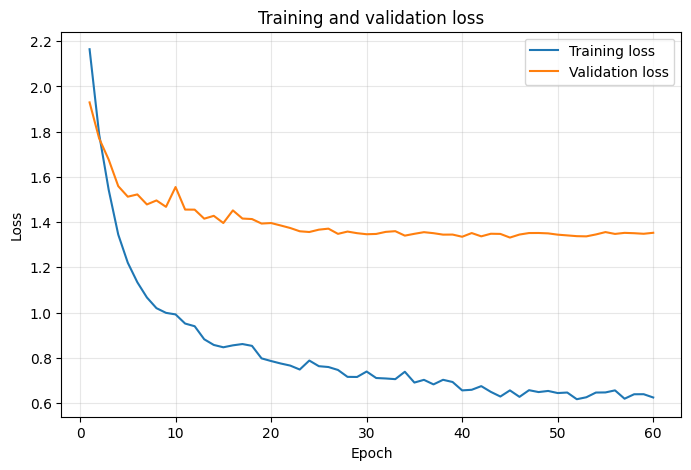

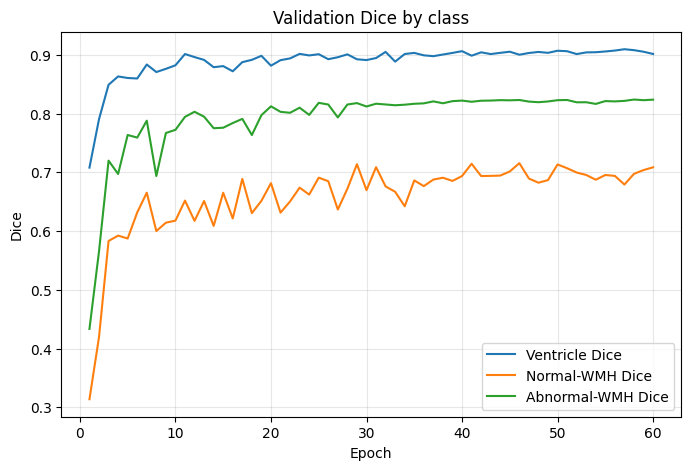

In [27]:
if "history" in globals() and len(history) > 0:
    display(history.tail(10))

    plt.figure(figsize=(8, 5))
    plt.plot(history["epoch"], history["train_loss"], label="Training loss")
    plt.plot(history["epoch"], history["val_loss"], label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title("Training and validation loss")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(history["epoch"], history["val_dice_vent"], label="Ventricle Dice")
    plt.plot(history["epoch"], history["val_dice_nwmh"], label="Normal-WMH Dice")
    plt.plot(history["epoch"], history["val_dice_abwmh"], label="Abnormal-WMH Dice")
    plt.xlabel("Epoch")
    plt.ylabel("Dice")
    plt.title("Validation Dice by class")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
else:
    print("No training history is available yet.")

## Full 60-epoch training summary

This section reports the best validation epochs and stability statistics for the complete Fold-3 run. It does not apply the old pilot go/no-go gate.


In [28]:
if "history" in globals() and len(history) > 0:
    required_columns = {
        "val_mean_fg_dice", "val_balanced_score", "val_weighted_score",
        "val_dice_vent", "val_dice_nwmh", "val_dice_abwmh",
        "mean_gradient_norm", "skipped_batches", "rollbacks_used",
    }
    missing_columns = required_columns - set(history.columns)
    if missing_columns:
        raise KeyError(
            f"Training history is missing required columns: {sorted(missing_columns)}"
        )

    best_balanced = history.loc[history["val_balanced_score"].idxmax()]
    best_fg = history.loc[history["val_mean_fg_dice"].idxmax()]
    best_normal = history.loc[history["val_dice_nwmh"].idxmax()]

    print("Best balanced-score epoch:")
    display(best_balanced.to_frame(name="value"))

    print("Best mean-foreground-Dice epoch:")
    display(best_fg.to_frame(name="value"))

    print("Best normal-WMH epoch:")
    display(best_normal.to_frame(name="value"))

    total_training_batches = int(math.ceil(len(train_ds) / BATCH_SIZE))
    maximum_skipped_rate = float(
        (history["skipped_batches"] / max(1, total_training_batches)).max()
    )
    maximum_gradient_norm = float(history["mean_gradient_norm"].max())
    maximum_rollbacks = int(history["rollbacks_used"].max())
    final_epoch = int(history["epoch"].max())

    print("Final completed epoch:", final_epoch)
    print("Maximum pre-clipping mean gradient norm:", maximum_gradient_norm)
    print("Maximum skipped-batch rate:", maximum_skipped_rate)
    print("Rollbacks used:", maximum_rollbacks)

    if final_epoch == 60:
        print("SUCCESS: all 60 configured epochs completed in this single run.")
    else:
        print(
            "WARNING: the run ended before epoch 60. Because ordinary early stopping "
            "is disabled, inspect the log for an instability safeguard, interruption, "
            "or Kaggle runtime issue."
        )

    print(
        "For model selection, use the saved best validation checkpoint rather than "
        "assuming the epoch-60 weights are automatically the best."
    )
else:
    print("No training history is available yet.")


Best balanced-score epoch:


,value
epoch,50
train_loss,0.643905
val_loss,1.344403
val_mean_fg_dice,0.81447
val_dice_vent,0.907085
val_dice_nwmh,0.713464
val_dice_abwmh,0.822862
val_weighted_score,0.795947
val_macro_score,0.81447
val_balanced_score,0.794653


Best mean-foreground-Dice epoch:


,value
epoch,50
train_loss,0.643905
val_loss,1.344403
val_mean_fg_dice,0.81447
val_dice_vent,0.907085
val_dice_nwmh,0.713464
val_dice_abwmh,0.822862
val_weighted_score,0.795947
val_macro_score,0.81447
val_balanced_score,0.794653


Best normal-WMH epoch:


,value
epoch,46
train_loss,0.627083
val_loss,1.344885
val_mean_fg_dice,0.81307
val_dice_vent,0.900331
val_dice_nwmh,0.715672
val_dice_abwmh,0.823205
val_weighted_score,0.795617
val_macro_score,0.813069
val_balanced_score,0.794138


Final completed epoch: 60
Maximum pre-clipping mean gradient norm: 71.87922341891267
Maximum skipped-batch rate: 0.006289308176100629
Rollbacks used: 0
SUCCESS: all 60 configured epochs completed in this single run.
For model selection, use the saved best validation checkpoint rather than assuming the epoch-60 weights are automatically the best.


## Verify and summarize the full-training checkpoint

This cell confirms that the best checkpoint and training history were saved successfully.


In [29]:
run_directory = (
    OUTPUT_DIR
    / RUN_NAME
)

best_checkpoint = (
    run_directory
    / "best_model.pt"
)

best_weighted_checkpoint = (
    run_directory
    / "best_weighted_model.pt"
)

best_nwmh_checkpoint = (
    run_directory
    / "best_nwmh_model.pt"
)

last_checkpoint = (
    run_directory
    / "last_checkpoint.pt"
)

history_path = (
    run_directory
    / "history.csv"
)

print(
    "Best balanced checkpoint:",
    best_checkpoint,
    "| exists:",
    best_checkpoint.exists(),
)

print(
    "Best weighted checkpoint:",
    best_weighted_checkpoint,
    "| exists:",
    best_weighted_checkpoint.exists(),
)

print(
    "Best normal-WMH checkpoint:",
    best_nwmh_checkpoint,
    "| exists:",
    best_nwmh_checkpoint.exists(),
)

print(
    "Latest resumable checkpoint:",
    last_checkpoint,
    "| exists:",
    last_checkpoint.exists(),
)

print(
    "Transfer ZIP:",
    "/kaggle/working/MS3SEG_V281_ABL_A4_NO_STOPGRAD_FOLD3_FULL60_TRANSFER.zip",
)

if history_path.exists():
    saved_history = pd.read_csv(
        history_path
    )

    print(
        "Best balanced-score epoch:"
    )

    display(
        saved_history.loc[
            saved_history[
                "val_balanced_score"
            ].idxmax()
        ].to_frame(
            name="value"
        )
    )

    print(
        "Best weighted-score epoch:"
    )

    display(
        saved_history.loc[
            saved_history[
                "val_weighted_score"
            ].idxmax()
        ].to_frame(
            name="value"
        )
    )

Best balanced checkpoint: /kaggle/working/ventimorph_v281_ablation_a4_no_stopgrad_fold3/v281_ablation_a4_no_stopgrad_fold3/best_model.pt | exists: True
Best weighted checkpoint: /kaggle/working/ventimorph_v281_ablation_a4_no_stopgrad_fold3/v281_ablation_a4_no_stopgrad_fold3/best_weighted_model.pt | exists: True
Best normal-WMH checkpoint: /kaggle/working/ventimorph_v281_ablation_a4_no_stopgrad_fold3/v281_ablation_a4_no_stopgrad_fold3/best_nwmh_model.pt | exists: True
Latest resumable checkpoint: /kaggle/working/ventimorph_v281_ablation_a4_no_stopgrad_fold3/v281_ablation_a4_no_stopgrad_fold3/last_checkpoint.pt | exists: True
Transfer ZIP: /kaggle/working/MS3SEG_V281_ABL_A4_NO_STOPGRAD_FOLD3_FULL60_TRANSFER.zip
Best balanced-score epoch:


,value
epoch,50
train_loss,0.643905
val_loss,1.344403
val_mean_fg_dice,0.81447
val_dice_vent,0.907085
val_dice_nwmh,0.713464
val_dice_abwmh,0.822862
val_weighted_score,0.795947
val_macro_score,0.81447
val_balanced_score,0.794653


Best weighted-score epoch:


,value
epoch,50
train_loss,0.643905
val_loss,1.344403
val_mean_fg_dice,0.81447
val_dice_vent,0.907085
val_dice_nwmh,0.713464
val_dice_abwmh,0.822862
val_weighted_score,0.795947
val_macro_score,0.81447
val_balanced_score,0.794653


## Save the trained model before leaving Kaggle

This packages the main checkpoint, the best-normal-WMH checkpoint, and
`history.csv` into one downloadable ZIP file.

In [30]:
transfer_zip = Path(
    "/kaggle/working/MS3SEG_V281_ABL_A4_NO_STOPGRAD_FOLD3_FULL60_TRANSFER.zip"
)

if transfer_zip.exists():
    print(
        "Transfer archive is ready:",
        transfer_zip,
    )

    print(
        "Download it now or save a Kaggle notebook version with outputs."
    )

else:
    print(
        "Transfer archive does not exist yet. "
        "At least one complete epoch must finish."
    )

Transfer archive is ready: /kaggle/working/MS3SEG_V281_ABL_A4_NO_STOPGRAD_FOLD3_FULL60_TRANSFER.zip
Download it now or save a Kaggle notebook version with outputs.


In [31]:
def build_input_slice(row, z):
    vols = [load_normalized_volume(row[k]) for k in ["flair", "t1", "t2"]]
    x = np.concatenate([MS3SEGVentiMorphDataset.triplet(v, z) for v in vols], axis=0)
    return torch.from_numpy(x.copy()).float()

@torch.no_grad()
def predict_patient(model, pid):
    model.eval()
    row = manifest_by_id.loc[str(pid).zfill(3)]
    target = compose_target(row)
    pred = np.zeros_like(target, dtype=np.uint8)
    uncertainty = np.zeros_like(target, dtype=np.float32)
    for z in range(target.shape[2]):
        out = model(build_input_slice(row, z).unsqueeze(0).to(DEVICE))
        pred[:, :, z] = out["segmentation_logits"].argmax(1).squeeze().cpu().numpy().astype(np.uint8)
        if out["uncertainty"] is not None:
            uncertainty[:, :, z] = out["uncertainty"].squeeze().cpu().numpy()
    return pred, target, uncertainty

In [32]:
def dice_binary(p, y, eps=1e-6):
    p, y = p.astype(bool), y.astype(bool)
    den = p.sum() + y.sum()
    return 1.0 if den == 0 else float((2*(p&y).sum()+eps)/(den+eps))

def iou_binary(p, y, eps=1e-6):
    p, y = p.astype(bool), y.astype(bool)
    u = (p|y).sum()
    return 1.0 if u == 0 else float(((p&y).sum()+eps)/(u+eps))

def hd95_binary(p, y, spacing):
    p, y = p.astype(bool), y.astype(bool)
    if not p.any() and not y.any(): return 0.0
    if not p.any() or not y.any(): return np.nan
    ps = np.logical_xor(p, ndimage.binary_erosion(p))
    ys = np.logical_xor(y, ndimage.binary_erosion(y))
    dt_y = ndimage.distance_transform_edt(~ys, sampling=spacing)
    dt_p = ndimage.distance_transform_edt(~ps, sampling=spacing)
    return float(np.percentile(np.concatenate([dt_y[ps], dt_p[ys]]), 95))

def lesion_metrics(p, y, min_voxels=3):
    st = ndimage.generate_binary_structure(3, 2)
    pl, pn = ndimage.label(p.astype(bool), structure=st)
    yl, yn = ndimage.label(y.astype(bool), structure=st)
    pc = [pl == i for i in range(1, pn+1) if (pl == i).sum() >= min_voxels]
    yc = [yl == i for i in range(1, yn+1) if (yl == i).sum() >= min_voxels]
    dt = sum(any((a&b).any() for b in pc) for a in yc)
    mp = sum(any((a&b).any() for b in yc) for a in pc)
    sens = dt/len(yc) if yc else 1.0
    prec = mp/len(pc) if pc else (1.0 if not yc else 0.0)
    f1 = 2*prec*sens/(prec+sens+1e-12)
    return {"lesion_sensitivity": sens, "lesion_precision": prec, "lesion_f1": f1,
            "true_lesions": len(yc), "pred_lesions": len(pc),
            "false_positive_lesions": max(0, len(pc)-mp)}

def periventricular_fp_rate(pred_ab, true_ab, vent, spacing_xy, max_mm=10.0):
    dist = np.zeros_like(vent, dtype=np.float32)
    for z in range(vent.shape[2]):
        dist[:, :, z] = ndimage.distance_transform_edt(~vent[:, :, z].astype(bool), sampling=spacing_xy)
    peri = (dist <= max_mm) & (~vent.astype(bool))
    fp = pred_ab & (~true_ab) & peri
    return float(fp.sum() / max(1, int((pred_ab & peri).sum())))

def evaluate_patients(model, ids, name):
    rows = []
    for pid in ids:
        pred, target, unc = predict_patient(model, pid)
        row = manifest_by_id.loc[pid]
        spacing = tuple(float(v) for v in nib.load(row.flair, mmap=True).header.get_zooms()[:3])
        result = {"patient_id": pid, "split": name}
        for c, n in [(1, "vent"), (2, "nwmh"), (3, "abwmh")]:
            result[f"dice_{n}"] = dice_binary(pred == c, target == c)
            result[f"iou_{n}"] = iou_binary(pred == c, target == c)
            result[f"hd95_{n}_mm"] = hd95_binary(pred == c, target == c, spacing)
        result.update({f"abwmh_{k}": v for k, v in lesion_metrics(pred == 3, target == 3).items()})
        result["periventricular_fp_rate"] = periventricular_fp_rate(
            pred == 3, target == 3, load_binary_mask(row.vent).astype(bool), spacing[:2]
        )
        err = pred != target
        result["mean_uncertainty"] = float(unc.mean())
        result["mean_uncertainty_error"] = float(unc[err].mean()) if err.any() else 0.0
        result["mean_uncertainty_correct"] = float(unc[~err].mean()) if (~err).any() else np.nan
        rows.append(result)
        print("Evaluated", pid)
    df = pd.DataFrame(rows)
    df.to_csv(OUTPUT_DIR / f"{name}_patient_metrics.csv", index=False)
    return df

In [33]:
RUN_TEST_EVALUATION = False
CHECKPOINT_PATH = OUTPUT_DIR / RUN_NAME / "best_model.pt"
if RUN_TEST_EVALUATION and not GPU_COMPATIBLE:
    raise RuntimeError(
        "RUN_TEST_EVALUATION requires a compatible CUDA GPU. Select T4 or another "
        "supported Kaggle GPU, restart the session, and Run All."
    )

if RUN_TEST_EVALUATION:
    ckpt = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
    cfg = ckpt["config"]
    test_model = VentiMorphRelNet(
        base=cfg["base"], use_multimodal=cfg["use_multimodal"],
        use_context=cfg["use_context"], guidance_mode=cfg["guidance_mode"],
        mid_guidance_mode=cfg.get("mid_guidance_mode", "vent"),
        use_prototypes=cfg["use_prototypes"], use_uncertainty=cfg["use_uncertainty"],
        deep_supervision=cfg.get("deep_supervision", True),
        mid_relation_residual=cfg.get("mid_relation_residual", 0.15),
        final_relation_residual=cfg.get("final_relation_residual", 0.25),
    ).to(DEVICE)
    test_model.load_state_dict(ckpt["model_state"])
    test_results = evaluate_patients(test_model, heldout_test_ids, "locked_test")
    display(test_results.describe())

In [34]:
# Nested/legacy ablation runner disabled.
# This notebook itself is one pre-specified ablation condition.
RUN_ABLATIONS = False
assert RUN_ABLATIONS is False


In [35]:
@torch.no_grad()
def visualize_prediction(model, pid, z=None):
    model.eval()
    row = manifest_by_id.loc[str(pid).zfill(3)]
    target = compose_target(row)
    flair = load_normalized_volume(row.flair)
    if z is None:
        z = int(np.argmax((target == 3).sum((0,1))))
    out = model(build_input_slice(row, z).unsqueeze(0).to(DEVICE))
    pred = out["segmentation_logits"].argmax(1).squeeze().cpu().numpy()
    vent = out["final_relation"]["vent_prob"].squeeze().cpu().numpy()
    radial = out["final_relation"].get("radial")
    radial = radial.squeeze().cpu().numpy() if radial is not None else np.zeros_like(vent)
    unc = out["uncertainty"].squeeze().cpu().numpy() if out["uncertainty"] is not None else np.zeros_like(vent)
    abp = torch.softmax(out["segmentation_logits"], 1)[:,3].squeeze().cpu().numpy()
    error = pred != target[:, :, z]

    fig, ax = plt.subplots(2, 4, figsize=(16,8))
    ims = [flair[:,:,z], target[:,:,z], pred, error, vent, radial, unc, abp]
    titles = ["FLAIR", "Ground truth", "Prediction", "Error", "Ventricle probability",
              "Radial alignment", "Uncertainty", "abWMH probability"]
    for a, im, title in zip(ax.ravel(), ims, titles):
        a.imshow(im, cmap="gray" if title not in ["Ground truth", "Prediction"] else "viridis")
        a.set_title(title)
        a.axis("off")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"qualitative_{pid}_{z}.png", dpi=250, bbox_inches="tight")
    plt.show()

In [36]:
metadata = {
    "model": "VentiMorph-RelNet-v2.8.1-ablation-A4_NO_STOPGRAD",
    "dataset_root": str(DATA_ROOT),
    "patients": int(len(manifest)),
    "input": "9-channel multimodal 2.5D FLAIR/T1/T2",
    "classes": {"0": "background", "1": "ventricle", "2": "normal_WMH", "3": "abnormal_WMH"},
    "primary_modules": [
        "per-pixel spatial modality-gated fusion",
        "adaptive anisotropic bottleneck context",
        "stop-gradient ventricle guidance at mid decoder",
        "zero-init bounded directional ventricle-relation refinement at final decoder",
        "deep supervision at d2/d1",
    ],
    "primary_training_excludes": [
        "relation-conditioned prototype loss",
        "evidential uncertainty loss",
    ],
    "split": "80 development patients with 5-fold CV and 20 locked test patients, unless official split is confirmed",
    "seed": SEED,
    "locked_test_evaluated": False,
}
with open(OUTPUT_DIR / "experiment_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print(json.dumps(metadata, indent=2))


{
  "model": "VentiMorph-RelNet-v2.8.1-ablation-A4_NO_STOPGRAD",
  "dataset_root": "/kaggle/input/datasets/saifsamiul/ms3seg/MS3SEG",
  "patients": 100,
  "input": "9-channel multimodal 2.5D FLAIR/T1/T2",
  "classes": {
    "0": "background",
    "1": "ventricle",
    "2": "normal_WMH",
    "3": "abnormal_WMH"
  },
  "primary_modules": [
    "per-pixel spatial modality-gated fusion",
    "adaptive anisotropic bottleneck context",
    "stop-gradient ventricle guidance at mid decoder",
    "zero-init bounded directional ventricle-relation refinement at final decoder",
    "deep supervision at d2/d1"
  ],
  "primary_training_excludes": [
    "relation-conditioned prototype loss",
    "evidential uncertainty loss"
  ],
  "split": "80 development patients with 5-fold CV and 20 locked test patients, unless official split is confirmed",
  "seed": 42,
  "locked_test_evaluated": false
}


## Kaggle instructions — Fold 3

1. Import this `.ipynb` into a fresh Kaggle notebook.
2. Attach **only the original MS3SEG dataset**.
3. Select **T4 GPU**.
4. Do not attach Fold-0 or previous-fold model checkpoints.
5. Use **Save Version → Save & Run All**. Training should run `E001 → E060` for Fold 3.
6. At completion, preserve `MS3SEG_V281_ABL_A4_NO_STOPGRAD_FOLD3_FULL60_TRANSFER.zip`.
7. Do not enable locked-test evaluation or ablations.
